# 04 · Métodos de interpretabilidade (Etapa 4, itens 1 a 3)

Explica os modelos avaliados no notebook 03 com três métodos, nesta ordem: **regras da árvore**, **importância por permutação** e **SHAP**. ALE/PDP, LIME/Anchors e contrafactuais (itens 4 a 6 do roadmap) ficam para depois.

**O que é explicado**
- **Ridge e árvore rasa no conjunto B** (atributos musicais + `release_period` + `artist_count`): os modelos com desempenho já avaliado e os melhores nos dois cenários de validação. Os conjuntos A e C entram só na permutação: A como controle (sem sinal no notebook 03) e C para medir quanto o modelo usa `main_artist`.
- Os modelos de cada fold são **reproduzidos** com as mesmas divisões (`cv_folds.json`) e os mesmos hiperparâmetros (`cv_results_by_fold.csv`) do notebook 03, e o notebook confere que as previsões batem com `predictions.csv`.
- Modelos finais (dados completos): a árvore salva no notebook 03 e uma Ridge escolhida com o mesmo protocolo.

**Como ler**
- As explicações descrevem o **comportamento do modelo**, não causas. Um atributo importante para o modelo não necessariamente aumenta os streams se for alterado.
- `streams` é acumulado. Por isso `release_period` mede, em boa parte, o **tempo de exposição** e a sobrevivência de músicas antigas numa lista de 2023, não uma escolha de composição.
- O alvo é `log1p(streams)`. Uma contribuição de $+\varphi$ na escala log equivale a multiplicar os streams previstos por cerca de $e^{\varphi}$ (ex.: $\varphi = -0{,}5 \Rightarrow \times 0{,}61$).
- Importâncias por permutação são medidas nos **folds de teste**, e a estabilidade é avaliada entre divisões dos dados.

Requer `shap` (ver `requirements.txt`). Rode com *Kernel → Restart & Run All*.

## Configuração, dados e utilitários

In [1]:
import copy, json, textwrap, warnings
from itertools import combinations
from math import factorial
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import sparse, stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

try:
    import shap
except ImportError as e:
    raise ImportError("shap não instalado: rode `pip install -r requirements.txt` no .venv do projeto") from e
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR, REPORTS_DIR = ROOT / "dataset" / "processed", ROOT / "reports"
FIG_DIR, TABLES_DIR, MODELS_DIR = REPORTS_DIR / "figures", REPORTS_DIR / "tables", REPORTS_DIR / "models"
for p in (FIG_DIR, TABLES_DIR, MODELS_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
N_PERM_REPEATS = 10             # repetições da permutação em cada fold
N_EXACT, N_EXACT_BG = 200, 100  # músicas explicadas e tamanho do fundo na conferência do Shapley exato (3.1)
sns.set_theme(style="whitegrid")

# --- Copiado do notebook 03 (a seção 0 confere que o resultado continua idêntico) ---
MIN_ARTIST_SONGS, INNER_SPLITS = 3, 3
PCT = ["danceability_%", "valence_%", "energy_%", "acousticness_%", "instrumentalness_%", "liveness_%", "speechiness_%"]
FEATURES = {"A": ["bpm", "key", "mode"] + PCT}
FEATURES["B"] = FEATURES["A"] + ["release_period", "artist_count"]
FEATURES["C"] = FEATURES["B"] + ["main_artist"]
NUMERIC = ["bpm", "artist_count"] + PCT
CATEG = ["key", "mode", "release_period"]
TARGET = "log_streams"
ALPHAS = np.logspace(-2, 3, 11)   # grade da Ridge no notebook 03

# --- Grupos de atributos, ordens e cores ---
FB = FEATURES["B"]
MUSICAIS = FEATURES["A"]
CONTEXTO = ["release_period", "artist_count"]
GRUPOS = {"musicais": MUSICAIS, "contexto": CONTEXTO, "artista": ["main_artist"]}
PERIODS = ["pre-2000", "2000-2017", "2018-2021", "2022", "2023"]
SCENARIOS, MODEL_NAMES = ["musica", "artista"], ["arvore", "ridge"]
SC_COLORS = {"musica": "#4C72B0", "artista": "#DD8452"}
GROUP_COLORS = {"musicais": "#55A868", "contexto": "#C44E52", "artista": "#8172B2"}

df = pd.read_csv(PROCESSED_DIR / "tracks_clean.csv", dtype={"key": str, "mode": str, "release_period": str})
d = df[df["usable_for_supervised"]].copy().reset_index(drop=True)
y = d[TARGET].to_numpy()
print(f"{len(d)} músicas para modelagem; {d['main_artist'].nunique()} artistas principais; shap {shap.__version__}")

CAPTIONS = []
def save_fig(fig, name, caption):
    """Salva a figura com a legenda (conclusão + n) embaixo, como nos notebooks 02 e 03.
    A margem inferior cresce com o número de linhas da legenda, para o texto não cobrir o eixo."""
    wrapped = textwrap.fill(caption, max(60, min(150, int(14 * fig.get_size_inches()[0]))))   # ~14 caracteres por polegada
    bottom = min(0.3, (0.25 + 0.17 * wrapped.count("\n")) / fig.get_size_inches()[1])
    fig.tight_layout(rect=[0, bottom, 1, 1])
    fig.text(0.01, 0.01, wrapped, fontsize=9, va="bottom")
    fig.savefig(FIG_DIR / name, dpi=130); plt.show(); CAPTIONS.append(dict(figura=name, legenda=caption)); print(name, "->", caption)

def milhoes(v):
    """log1p(streams) -> streams em milhões."""
    return np.expm1(v) / 1e6

952 músicas para modelagem; 458 artistas principais; shap 0.49.1


## 0. Reproduzir os modelos avaliados no notebook 03

Para interpretar **exatamente** os modelos cujo desempenho foi medido, cada modelo dos folds externos (2 cenários × 3 repetições × 5 folds, conjuntos A, B e C) é reajustado com as mesmas divisões (`cv_folds.json`) e os hiperparâmetros que a CV aninhada escolheu naquele fold (`best_params` em `cv_results_by_fold.csv`), sem refazer a busca. Ridge e árvore (com `random_state` fixo) são determinísticas, então as previsões no teste precisam coincidir com `predictions.csv`. O `assert` também garante que o código copiado do notebook 03 continua em sincronia com ele.

Também são montados os **modelos finais** do conjunto B: a árvore salva no notebook 03 (`tree_full_B.joblib`) e uma Ridge escolhida pelo mesmo protocolo (busca com `GroupKFold` por música nos dados completos), salva em `ridge_full_B.joblib` para as próximas partes da Etapa 4.

`split_info` liga cada coluna da matriz transformada (após imputação, padronização e one-hot) ao atributo original. É o que permite ler limiares em unidades originais e somar os SHAP das dummies de um mesmo atributo.

In [2]:
class RareToOther(BaseEstimator, TransformerMixin):
    def __init__(self, min_count=3):
        self.min_count = min_count
    def fit(self, X, y=None):
        vc = pd.Series(np.asarray(X).ravel().astype(str)).value_counts()
        self.keep_ = set(vc[vc >= self.min_count].index)
        return self
    def transform(self, X):
        s = pd.Series(np.asarray(X).ravel().astype(str))
        return s.where(s.isin(self.keep_), "outros").to_frame().to_numpy()

def make_pipeline(feats, model, scale=True):
    """Igual ao notebook 03; scale=False só retira o StandardScaler (usado para desenhar a árvore)."""
    num = [f for f in feats if f in NUMERIC]
    cat = [f for f in feats if f in CATEG]
    parts = []
    if num: parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median"))] +
                                          ([("sc", StandardScaler())] if scale else [])), num))
    if cat: parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                                           ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat))
    if "main_artist" in feats:
        parts.append(("art", Pipeline([("rare", RareToOther(MIN_ARTIST_SONGS)),
                                       ("ohe", OneHotEncoder(handle_unknown="ignore"))]), ["main_artist"]))
    return Pipeline([("prep", ColumnTransformer(parts)), ("model", model)])

ESTIMATORS = {"ridge": Ridge(), "arvore": DecisionTreeRegressor(random_state=SEED)}

def split_info(prep):
    """Para cada coluna transformada: atributo original, tipo (num/cat), categoria e média/escala do StandardScaler."""
    info = []
    for name, trans, cols in prep.transformers_:
        if name == "num":
            sc = trans.named_steps.get("sc")
            for j, c in enumerate(cols):
                info.append(dict(feature=c, kind="num", category=None,
                                 mu=sc.mean_[j] if sc is not None else 0.0, s=sc.scale_[j] if sc is not None else 1.0))
        elif name in ("cat", "art"):
            for c, cats in zip(cols, trans.named_steps["ohe"].categories_):
                info += [dict(feature=c, kind="cat", category=str(v), mu=0.0, s=1.0) for v in cats]
    assert len(info) == sum(s.stop - s.start for s in prep.output_indices_.values()), "colunas transformadas sem dono"
    return info

def to_dense(X):
    return X.toarray() if sparse.issparse(X) else np.asarray(X)

# --- Divisões, hiperparâmetros e previsões salvas pelo notebook 03 ---
folds = json.load(open(TABLES_DIR / "cv_folds.json"))
cvres = pd.read_csv(TABLES_DIR / "cv_results_by_fold.csv")
saved = pd.read_csv(TABLES_DIR / "predictions.csv")
pos = pd.Series(np.arange(len(d)), index=d["row_id"].to_numpy())          # row_id -> posição em d
TRAIN_IDX, TEST_IDX = {}, {}
for sc, lst in folds.items():
    for f in lst:
        TRAIN_IDX[(sc, f["rep"], f["fold"])] = pos.loc[f["train_row_id"]].to_numpy()
        TEST_IDX[(sc, f["rep"], f["fold"])] = pos.loc[f["test_row_id"]].to_numpy()
best = cvres[cvres.modelo != "baseline"].set_index(["cenario", "rep", "fold", "modelo", "conjunto"])["best_params"]
saved_pred = {k: g.set_index("row_id")["y_pred"] for k, g in saved.groupby(["cenario", "rep", "fold", "modelo", "conjunto"])}

FITTED, diffs = {}, []
for (sc, r, k), tr in TRAIN_IDX.items():
    te = TEST_IDX[(sc, r, k)]
    for m, est in ESTIMATORS.items():
        for c, feats in FEATURES.items():
            pipe = make_pipeline(feats, clone(est)).set_params(**json.loads(best.loc[(sc, r, k, m, c)]))
            pipe.fit(d.iloc[tr][feats], y[tr])
            yp = pipe.predict(d.iloc[te][feats])
            diffs.append(np.abs(yp - saved_pred[(sc, r, k, m, c)].loc[d["row_id"].iloc[te]].to_numpy()).max())
            FITTED[(sc, r, k, m, c)] = pipe
print(f"{len(FITTED)} modelos de fold reajustados; maior diferença para predictions.csv = {max(diffs):.1e}")
assert max(diffs) < 1e-8, "previsões diferentes das do notebook 03: código ou artefatos fora de sincronia"

# --- Modelos finais do conjunto B (dados completos) ---
tree_final = joblib.load(MODELS_DIR / "tree_full_B.joblib")
gs = GridSearchCV(make_pipeline(FB, Ridge()), {"model__alpha": ALPHAS}, cv=GroupKFold(INNER_SPLITS),
                  scoring="neg_mean_absolute_error").fit(d[FB], y, groups=d["song_group"].to_numpy())
ridge_final = gs.best_estimator_
joblib.dump(ridge_final, MODELS_DIR / "ridge_full_B.joblib")
FINAL = {"arvore": tree_final, "ridge": ridge_final}
tm_final = tree_final.named_steps["model"]
print(f"Árvore final: max_depth={tm_final.max_depth}, min_samples_leaf={tm_final.min_samples_leaf} | "
      f"Ridge final: alpha={gs.best_params_['model__alpha']:.3g} (salva em ridge_full_B.joblib)")

180 modelos de fold reajustados; maior diferença para predictions.csv = 3.6e-15


Árvore final: max_depth=3, min_samples_leaf=20 | Ridge final: alpha=3.16 (salva em ridge_full_B.joblib)


## 1. Regras da árvore

### 1.1 A árvore final

A árvore final (conjunto B, com profundidade e folha mínima escolhidas por CV no notebook 03) é a "fórmula" mais legível que os dados sustentam. Uma árvore depende só da **ordem** dos valores, então retirar o `StandardScaler` não muda nenhuma divisão. Ela é reajustada sem o scaler apenas para desenhar os limiares em unidades originais, e o notebook confere que as previsões são idênticas.

Na tabela de folhas, as condições sobre dummies viram conjuntos (ex.: `release_period ∈ {pre-2000, 2018-2021}`), e limiares repetidos no mesmo atributo viram intervalos. A previsão da folha é a média de `log1p(streams)` das músicas dela. Convertida com `expm1`, dá um valor "típico" de streams: próximo da média geométrica e abaixo da média aritmética.

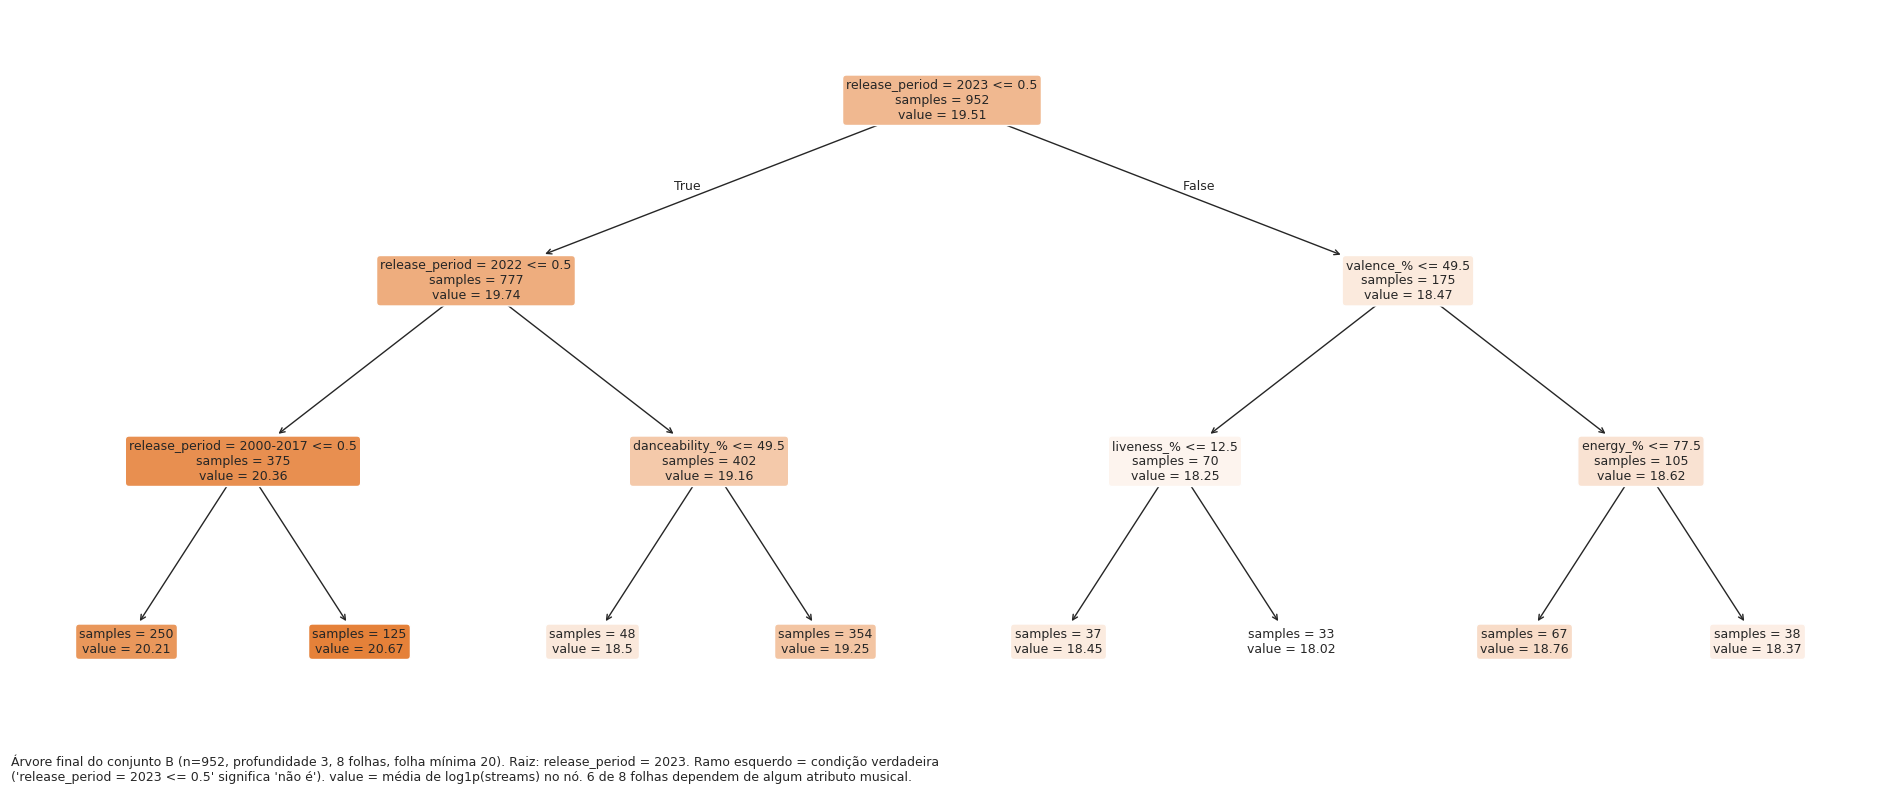

fig_tree_B.png -> Árvore final do conjunto B (n=952, profundidade 3, 8 folhas, folha mínima 20). Raiz: release_period = 2023. Ramo esquerdo = condição verdadeira ('release_period = 2023 <= 0.5' significa 'não é'). value = média de log1p(streams) no nó. 6 de 8 folhas dependem de algum atributo musical.


,regra,n,n_artistas,pred_log,pred_streams_M,mediana_streams_M,iqr_log,usa_musical
0,release_period = 2000-2017,125,85,20.67,943.90,1089.40,0.94,False
1,"release_period ∈ {pre-2000, 2018-2021}",250,172,20.21,598.83,597.96,1.16,False
2,release_period = 2022 e danceability_% > 49.5,354,197,19.25,228.80,235.80,0.85,True
3,release_period = 2023 e valence_% > 49.5 e energy_% ≤ 77.5,67,56,18.76,140.62,144.57,1.06,True
4,release_period = 2022 e danceability_% ≤ 49.5,48,30,18.50,108.26,133.81,1.36,True
5,release_period = 2023 e valence_% ≤ 49.5 e liveness_% ≤ 12.5,37,31,18.45,103.04,115.01,1.04,True
6,release_period = 2023 e valence_% > 49.5 e energy_% > 77.5,38,31,18.37,95.35,98.34,0.69,True
7,release_period = 2023 e valence_% ≤ 49.5 e liveness_% > 12.5,33,29,18.02,67.12,67.07,0.88,True


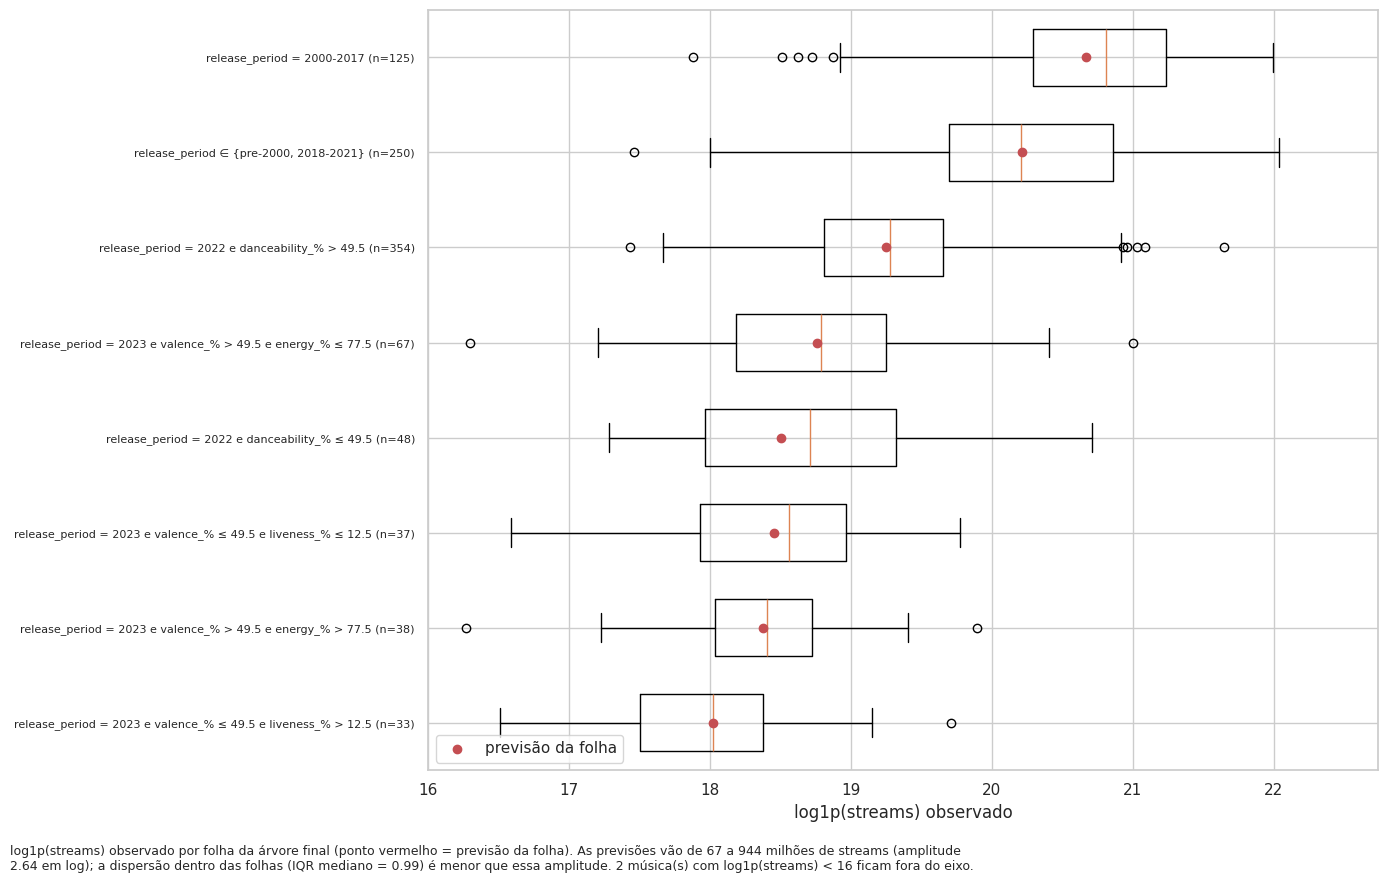

fig_tree_leaves.png -> log1p(streams) observado por folha da árvore final (ponto vermelho = previsão da folha). As previsões vão de 67 a 944 milhões de streams (amplitude 2.64 em log); a dispersão dentro das folhas (IQR mediano = 0.99) é menor que essa amplitude. 2 música(s) com log1p(streams) < 16 ficam fora do eixo.


In [3]:
def fmt_num(x):
    return f"{x:.0f}" if abs(x - round(x)) < 1e-6 else f"{x:.1f}"

def fmt_cond(f, v, all_cats):
    """Condição acumulada num caminho: intervalo (numérico) ou conjunto de categorias."""
    if isinstance(v, (set, frozenset)):
        if v == all_cats[f]:
            return ""
        cats = [c for c in (PERIODS if f == "release_period" else sorted(v)) if c in v]
        return f"{f} = {cats[0]}" if len(cats) == 1 else f"{f} ∈ {{{', '.join(cats)}}}"
    lo, hi = v
    if np.isfinite(lo) and np.isfinite(hi):
        return f"{fmt_num(lo)} < {f} ≤ {fmt_num(hi)}"
    return f"{f} ≤ {fmt_num(hi)}" if np.isfinite(hi) else f"{f} > {fmt_num(lo)}"

def tree_leaves(pipe):
    """Cada folha da árvore como uma regra legível, em unidades originais."""
    info, t = split_info(pipe.named_steps["prep"]), pipe.named_steps["model"].tree_
    all_cats = {}
    for i in info:
        if i["kind"] == "cat":
            all_cats.setdefault(i["feature"], set()).add(i["category"])
    rows = []
    def walk(node, cond):
        left, right = t.children_left[node], t.children_right[node]
        if left == -1:
            parts = {f: fmt_cond(f, v, all_cats) for f, v in cond.items()}
            rows.append(dict(folha=node, regra=" e ".join(p for p in parts.values() if p) or "(todas)",
                             n_treino=int(t.n_node_samples[node]), pred_log=float(t.value[node].ravel()[0]),
                             usa_musical=any(p and f in MUSICAIS for f, p in parts.items())))
            return
        i = info[t.feature[node]]; f = i["feature"]
        if i["kind"] == "num":
            thr = t.threshold[node] * i["s"] + i["mu"]            # desfaz a padronização
            lo, hi = cond.get(f, (-np.inf, np.inf))
            walk(left, {**cond, f: (lo, min(hi, thr))}); walk(right, {**cond, f: (max(lo, thr), hi)})
        else:                                                    # dummy: <= 0.5 -> não é a categoria
            cur = cond.get(f, all_cats[f])
            walk(left, {**cond, f: cur - {i["category"]}}); walk(right, {**cond, f: cur & {i["category"]}})
    walk(0, {})
    return pd.DataFrame(rows)

# Árvore sem scaler: mesmas divisões, limiares em unidades originais (só para o desenho)
tree_plot = make_pipeline(FB, clone(tm_final), scale=False).fit(d[FB], y)
assert np.array_equal(tree_plot.predict(d[FB]), tree_final.predict(d[FB])), "árvore sem scaler difere da final"
leaves = tree_leaves(tree_final)
assert leaves["regra"].tolist() == tree_leaves(tree_plot)["regra"].tolist(), "limiares desfeitos não batem"

info_plot = split_info(tree_plot.named_steps["prep"])
pretty = [i["feature"] if i["kind"] == "num" else f'{i["feature"]} = {i["category"]}' for i in info_plot]
tm_plot = tree_plot.named_steps["model"]
root = info_plot[tm_plot.tree_.feature[0]]
root_txt = (f'{root["feature"]} = {root["category"]}' if root["kind"] == "cat"
            else f'{root["feature"]} ≤ {fmt_num(tm_plot.tree_.threshold[0])}')
fig, ax = plt.subplots(figsize=(19, 8))
plot_tree(tm_plot, feature_names=pretty, filled=True, rounded=True, impurity=False, precision=2, fontsize=9, ax=ax)
save_fig(fig, "fig_tree_B.png",
         f"Árvore final do conjunto B (n={len(d)}, profundidade {tm_plot.get_depth()}, {tm_plot.get_n_leaves()} folhas, "
         f"folha mínima {tm_plot.min_samples_leaf}). Raiz: {root_txt}. Ramo esquerdo = condição verdadeira "
         f"('{root_txt} <= 0.5' significa 'não é'). value = média de log1p(streams) no nó. "
         f"{int(leaves['usa_musical'].sum())} de {len(leaves)} folhas dependem de algum atributo musical.")

# Estatísticas observadas por folha
leaf_of = tm_final.apply(to_dense(tree_final.named_steps["prep"].transform(d[FB])).astype(np.float32))
g = d.assign(folha=leaf_of).groupby("folha")
leaves = leaves.join(pd.DataFrame(dict(n=g.size(), n_artistas=g["main_artist"].nunique(),
                                       mediana_streams_M=g["streams"].median() / 1e6,
                                       iqr_log=g[TARGET].quantile(.75) - g[TARGET].quantile(.25))), on="folha")
assert (leaves["n"] == leaves["n_treino"]).all()
leaves["pred_streams_M"] = milhoes(leaves["pred_log"])
leaves = leaves.sort_values("pred_log", ascending=False).reset_index(drop=True)
leaves.to_csv(TABLES_DIR / "tab_tree_leaves.csv", index=False)
with pd.option_context("display.max_colwidth", 100, "display.width", 250):
    display(leaves[["regra", "n", "n_artistas", "pred_log", "pred_streams_M", "mediana_streams_M", "iqr_log", "usa_musical"]].round(2))

fig, ax = plt.subplots(figsize=(14, 0.8 * len(leaves) + 2.5))
ax.boxplot([d.loc[leaf_of == f, TARGET] for f in leaves["folha"]], vert=False, positions=range(len(leaves)), widths=.6)
ax.scatter(leaves["pred_log"], range(len(leaves)), color="#C44E52", zorder=3, label="previsão da folha")
ax.set_yticks(range(len(leaves)))
ax.set_yticklabels([textwrap.fill(f"{r} (n={n})", 75) for r, n in zip(leaves["regra"], leaves["n"])], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("log1p(streams) observado"); ax.legend(loc="lower left")
xmin = np.floor(np.quantile(y, 0.005)); n_out = int((y < xmin).sum()); ax.set_xlim(left=xmin)
spread, iqr_med = leaves["pred_log"].max() - leaves["pred_log"].min(), leaves["iqr_log"].median()
save_fig(fig, "fig_tree_leaves.png",
         f"log1p(streams) observado por folha da árvore final (ponto vermelho = previsão da folha). As previsões vão de "
         f"{leaves['pred_streams_M'].min():.0f} a {leaves['pred_streams_M'].max():.0f} milhões de streams (amplitude {spread:.2f} em log); "
         f"a dispersão dentro das folhas (IQR mediano = {iqr_med:.2f}) é {'maior' if iqr_med > spread else 'menor'} que essa amplitude."
         + (f" {n_out} música(s) com log1p(streams) < {xmin:.0f} ficam fora do eixo." if n_out else ""))

### 1.2 As regras mudam entre divisões dos dados?

Uma regra só vale como padrão se reaparecer quando os dados mudam. Aqui entram as 15 árvores B de cada cenário (uma por fold externo, com os hiperparâmetros escolhidos naquele fold), já reproduzidas na seção 0:

- **Uso de atributos:** em quantas árvores cada atributo aparece em algum nó, nos dois primeiros níveis ou na raiz.
- **Raiz:** qual regra abre a árvore.
- **Limiares:** onde ficam os cortes dos atributos numéricos, em unidades originais.
- **Concordância funcional:** Spearman entre as previsões de pares de árvores nas 952 músicas. Árvores com regras diferentes ainda podem ordenar as músicas de forma parecida.

Parte da variação vem dos hiperparâmetros (a profundidade e a folha mínima mudam entre folds), e isso também é instabilidade do procedimento.

Hiperparâmetros escolhidos nos folds (árvore B):


,cenario,max_depth,min_samples_leaf,n_folds
0,artista,3,20,4
1,artista,3,40,9
2,artista,4,10,1
3,artista,4,20,1
4,musica,2,5,1
5,musica,2,20,1
6,musica,3,20,2
7,musica,3,40,10
8,musica,4,20,1


Regra da raiz:


,cenario,condicao,n_arvores,pct
1,artista,release_period = 2023,13,86.7
0,artista,release_period = 2000-2017,2,13.3
3,musica,release_period = 2023,14,93.3
2,musica,release_period = 2000-2017,1,6.7


Limiares numéricos (unidades originais):


,cenario,feature,n_cortes,mediana,minimo,maximo,n_arvores
0,artista,acousticness_%,9,17.5,4.5,66.5,7
1,artista,artist_count,2,2.5,2.5,2.5,2
2,artista,danceability_%,12,50.2,49.5,70.5,12
3,artista,energy_%,11,72.5,69.0,78.5,9
4,artista,instrumentalness_%,1,2.5,2.5,2.5,1
5,artista,liveness_%,4,14.0,12.5,17.0,4
6,artista,speechiness_%,5,10.5,7.0,31.5,4
7,artista,valence_%,15,49.5,46.0,67.5,13
8,musica,acousticness_%,6,18.5,13.5,28.5,5
9,musica,bpm,1,135.5,135.5,135.5,1


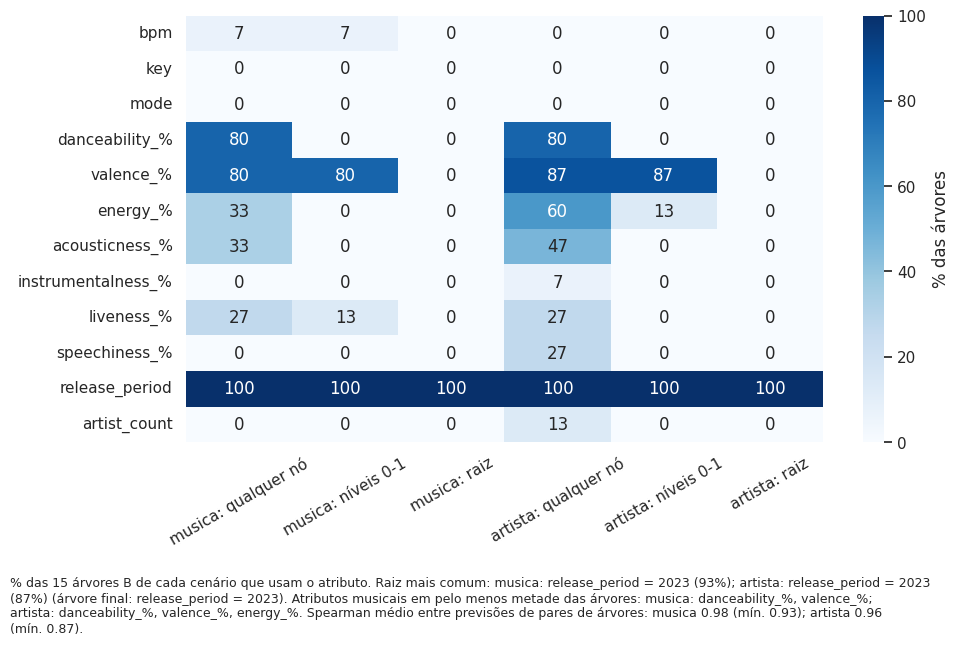

fig_tree_stability.png -> % das 15 árvores B de cada cenário que usam o atributo. Raiz mais comum: musica: release_period = 2023 (93%); artista: release_period = 2023 (87%) (árvore final: release_period = 2023). Atributos musicais em pelo menos metade das árvores: musica: danceability_%, valence_%; artista: danceability_%, valence_%, energy_%. Spearman médio entre previsões de pares de árvores: musica 0.98 (mín. 0.93); artista 0.96 (mín. 0.87).


In [4]:
def tree_splits(pipe):
    """Nós internos: profundidade, atributo original e condição em unidades originais."""
    info, t = split_info(pipe.named_steps["prep"]), pipe.named_steps["model"].tree_
    depth, rows = np.zeros(t.node_count, int), []
    for node in range(t.node_count):        # filhos têm índice maior que o pai
        for ch in (t.children_left[node], t.children_right[node]):
            if ch != -1:
                depth[ch] = depth[node] + 1
        if t.children_left[node] == -1:
            continue
        i = info[t.feature[node]]
        thr = t.threshold[node] * i["s"] + i["mu"]
        rows.append(dict(no=node, profundidade=int(depth[node]), feature=i["feature"], n=int(t.n_node_samples[node]),
                         condicao=f'{i["feature"]} = {i["category"]}' if i["kind"] == "cat" else f'{i["feature"]} ≤ {fmt_num(thr)}',
                         limiar=thr if i["kind"] == "num" else np.nan))
    return pd.DataFrame(rows)

parts, preds_trees, hp = [], {sc: [] for sc in SCENARIOS}, []
for (sc, r, k, m, c), pipe in FITTED.items():
    if (m, c) != ("arvore", "B"):
        continue
    parts.append(tree_splits(pipe).assign(cenario=sc, rep=r, fold=k))
    preds_trees[sc].append(pipe.predict(d[FB]))
    t = pipe.named_steps["model"]
    hp.append(dict(cenario=sc, max_depth=t.max_depth, min_samples_leaf=t.min_samples_leaf, folhas=t.get_n_leaves()))
splits = pd.concat(parts, ignore_index=True)
n_trees = {sc: len(preds_trees[sc]) for sc in SCENARIOS}

def pct_trees(sub, sc):
    return 100 * sub.drop_duplicates(["rep", "fold", "feature"]).groupby("feature").size() / n_trees[sc]

stab = pd.concat([pd.DataFrame({"qualquer_no": pct_trees(s, sc), "nivel_0_1": pct_trees(s[s.profundidade <= 1], sc),
                                "raiz": pct_trees(s[s.profundidade == 0], sc)}).reindex(FB).fillna(0).assign(cenario=sc)
                  for sc in SCENARIOS for s in [splits[splits.cenario == sc]]]).rename_axis("feature").reset_index()
stab.to_csv(TABLES_DIR / "tab_tree_stability.csv", index=False)

roots = (splits[splits.profundidade == 0].groupby(["cenario", "condicao"]).size().rename("n_arvores").reset_index()
         .assign(pct=lambda t: 100 * t.n_arvores / t.cenario.map(n_trees))
         .sort_values(["cenario", "n_arvores"], ascending=[True, False]))
roots.to_csv(TABLES_DIR / "tab_tree_roots.csv", index=False)
top_root = roots.groupby("cenario").head(1).set_index("cenario")
final_root = tree_splits(tree_final).query("profundidade == 0")["condicao"].iloc[0]

num_splits = splits.dropna(subset=["limiar"])
thr_tab = (num_splits.groupby(["cenario", "feature"])["limiar"].agg(n_cortes="size", mediana="median", minimo="min", maximo="max")
           .join(num_splits.drop_duplicates(["cenario", "rep", "fold", "feature"]).groupby(["cenario", "feature"]).size().rename("n_arvores"))
           .reset_index())
thr_tab.to_csv(TABLES_DIR / "tab_tree_thresholds.csv", index=False)

agree = {}
for sc, P in preds_trees.items():
    R = stats.spearmanr(np.column_stack(P))[0]
    agree[sc] = R[np.triu_indices_from(R, 1)]

print("Hiperparâmetros escolhidos nos folds (árvore B):")
display(pd.DataFrame(hp).groupby(["cenario", "max_depth", "min_samples_leaf"]).size().rename("n_folds").reset_index())
print("Regra da raiz:"); display(roots.round(1))
print("Limiares numéricos (unidades originais):"); display(thr_tab.round(1))

piv = pd.DataFrame({f"{sc}: {lab}": stab[stab.cenario == sc].set_index("feature")[col]
                    for sc in SCENARIOS for col, lab in [("qualquer_no", "qualquer nó"), ("nivel_0_1", "níveis 0-1"), ("raiz", "raiz")]}).reindex(FB)
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(piv, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% das árvores"})
ax.set_ylabel(""); ax.tick_params(axis="x", rotation=30)
mus_half = {sc: stab[(stab.cenario == sc) & stab.feature.isin(MUSICAIS) & (stab.qualquer_no >= 50)].feature.tolist() for sc in SCENARIOS}
save_fig(fig, "fig_tree_stability.png",
         f"% das {n_trees['musica']} árvores B de cada cenário que usam o atributo. Raiz mais comum: " +
         "; ".join(f"{sc}: {top_root.loc[sc, 'condicao']} ({top_root.loc[sc, 'pct']:.0f}%)" for sc in SCENARIOS) +
         f" (árvore final: {final_root}). Atributos musicais em pelo menos metade das árvores: " +
         "; ".join(f"{sc}: {', '.join(v) or 'nenhum'}" for sc, v in mus_half.items()) +
         ". Spearman médio entre previsões de pares de árvores: " +
         "; ".join(f"{sc} {agree[sc].mean():.2f} (mín. {agree[sc].min():.2f})" for sc in SCENARIOS) + ".")

### 1.3 O modelo linear: coeficientes da Ridge B

Na Ridge, a "regra" é o coeficiente. Como os atributos numéricos estão padronizados, o coeficiente é o efeito de +1 desvio-padrão do atributo na previsão de `log1p(streams)`, com os demais fixos, e $100\,(e^{\beta}-1)$ traduz esse efeito em % de streams previstos. A tabela traz a Ridge final e as 15 Ridges B do cenário por música, e conta em quantos folds o sinal coincide com o do modelo final. Sinal instável indica que o modelo não aprendeu uma direção confiável.

As dummies (tonalidade, modo e período) não têm categoria de referência. Com a penalização, a solução tem soma zero dentro de cada atributo, então cada coeficiente é um desvio em relação à média das categorias.

,coef_final,media_folds,dp_folds,pct_mesmo_sinal,efeito_pct_streams
coluna,,,,,
bpm,0.035,0.034,0.015,100.000,3.517
danceability_%,0.089,0.087,0.024,100.000,9.342
valence_%,-0.025,-0.024,0.021,86.667,-2.476
energy_%,0.003,0.003,0.018,53.333,0.291
acousticness_%,-0.025,-0.026,0.020,86.667,-2.505
instrumentalness_%,-0.067,-0.066,0.018,100.000,-6.473
liveness_%,0.004,0.004,0.010,60.000,0.426
speechiness_%,-0.073,-0.073,0.021,100.000,-7.047
artist_count,-0.087,-0.088,0.018,100.000,-8.369


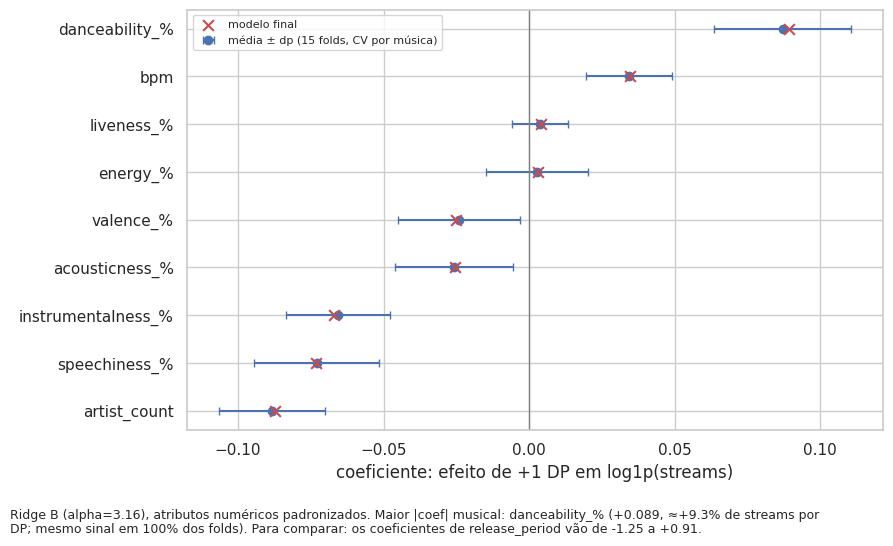

fig_ridge_coef.png -> Ridge B (alpha=3.16), atributos numéricos padronizados. Maior |coef| musical: danceability_% (+0.089, ≈+9.3% de streams por DP; mesmo sinal em 100% dos folds). Para comparar: os coeficientes de release_period vão de -1.25 a +0.91.


In [5]:
def coef_series(pipe):
    info = split_info(pipe.named_steps["prep"])
    names = [i["feature"] if i["kind"] == "num" else f'{i["feature"]} = {i["category"]}' for i in info]
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

coef_final = coef_series(ridge_final)
coef_folds = pd.DataFrame([coef_series(p) for (sc, r, k, m, c), p in FITTED.items() if (sc, m, c) == ("musica", "ridge", "B")])
coef = pd.DataFrame({"coef_final": coef_final, "media_folds": coef_folds.mean(), "dp_folds": coef_folds.std(),
                     "pct_mesmo_sinal": 100 * (np.sign(coef_folds) == np.sign(coef_final)).mean()})
coef["efeito_pct_streams"] = 100 * np.expm1(coef["coef_final"])
coef.index.name = "coluna"
coef.to_csv(TABLES_DIR / "tab_ridge_coef.csv")
display(coef.round(3))

sub = coef.loc[[c for c in coef.index if c in NUMERIC]].sort_values("coef_final")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(sub["media_folds"], range(len(sub)), xerr=sub["dp_folds"], fmt="o", color="#4C72B0", capsize=3,
            label=f"média ± dp ({len(coef_folds)} folds, CV por música)")
ax.scatter(sub["coef_final"], range(len(sub)), marker="x", s=60, color="#C44E52", zorder=3, label="modelo final")
ax.axvline(0, color="gray", lw=1); ax.set_yticks(range(len(sub))); ax.set_yticklabels(sub.index)
ax.set_xlabel("coeficiente: efeito de +1 DP em log1p(streams)"); ax.legend(fontsize=8)
per = coef.loc[[c for c in coef.index if c.startswith("release_period")], "coef_final"]
big = sub.loc[[c for c in sub.index if c in MUSICAIS], "coef_final"].abs().idxmax()
save_fig(fig, "fig_ridge_coef.png",
         f"Ridge B (alpha={ridge_final.named_steps['model'].alpha:.3g}), atributos numéricos padronizados. Maior |coef| musical: {big} "
         f"({coef.loc[big, 'coef_final']:+.3f}, ≈{coef.loc[big, 'efeito_pct_streams']:+.1f}% de streams por DP; mesmo sinal em "
         f"{coef.loc[big, 'pct_mesmo_sinal']:.0f}% dos folds). Para comparar: os coeficientes de release_period vão de "
         f"{per.min():+.2f} a {per.max():+.2f}.")

## 2. Importância por permutação (dados de avaliação)

Para cada modelo de fold, uma coluna **do fold de teste** é embaralhada e mede-se quanto o MAE aumenta (`permutation_importance`, `scoring="neg_mean_absolute_error"`, `N_PERM_REPEATS` repetições). A permutação é aplicada à entrada do pipeline, então atributos categóricos (`key`, `release_period`, `main_artist`) são permutados inteiros, antes do one-hot.

- Valor ≈ 0: o modelo não depende do atributo para errar menos em músicas que não viu. Valor negativo: permutar até ajudou (ruído).
- Atributos correlacionados dividem a importância (ex.: `energy_%` × `acousticness_%`, |rho| = 0,48 no notebook 02), e a permutação pode criar combinações irreais.
- No cenário por artista, todos os artistas de teste são desconhecidos para o conjunto C (caem em "outros"), então a importância de `main_artist` é zero por construção.

Aumento médio do MAE (log1p) ao permutar, conjunto B:


cenario            artista          musica        
modelo              arvore   ridge  arvore   ridge
feature                                           
bpm                 0.0000  0.0010 -0.0005  0.0003
key                 0.0000 -0.0032  0.0000 -0.0035
mode                0.0000 -0.0016  0.0000 -0.0017
danceability_%      0.0111  0.0057  0.0126  0.0073
valence_%           0.0039 -0.0007  0.0035 -0.0002
energy_%           -0.0003 -0.0005  0.0004 -0.0006
acousticness_%      0.0003 -0.0006 -0.0005  0.0004
instrumentalness_%  0.0002  0.0040  0.0000  0.0037
liveness_%          0.0005 -0.0002  0.0001 -0.0000
speechiness_%      -0.0005  0.0064  0.0000  0.0058
release_period      0.4398  0.4319  0.4503  0.4283
artist_count        0.0002  0.0092  0.0000  0.0092

Conjunto C, main_artist:


,cenario,modelo,conjunto,feature,media,dp,minimo,maximo,pct_folds_positivo,rank
33,artista,arvore,C,main_artist,0.0000,0.0000,0.0000,0.0000,0.0000,12
63,artista,ridge,C,main_artist,0.0000,0.0000,0.0000,0.0000,0.0000,7
94,musica,arvore,C,main_artist,0.0082,0.0112,-0.0002,0.0309,46.6667,3
128,musica,ridge,C,main_artist,0.0298,0.0092,0.0138,0.0487,100.0000,2


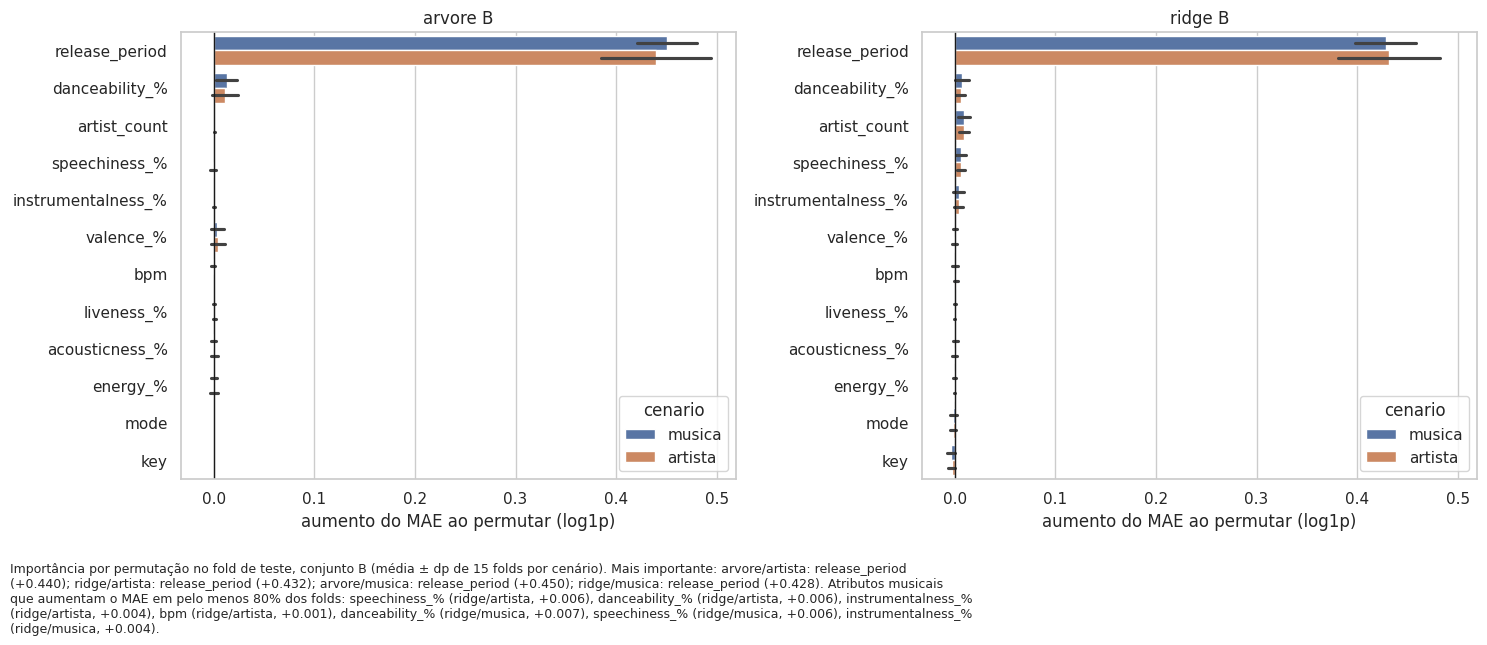

fig_perm_importance.png -> Importância por permutação no fold de teste, conjunto B (média ± dp de 15 folds por cenário). Mais importante: arvore/artista: release_period (+0.440); ridge/artista: release_period (+0.432); arvore/musica: release_period (+0.450); ridge/musica: release_period (+0.428). Atributos musicais que aumentam o MAE em pelo menos 80% dos folds: speechiness_% (ridge/artista, +0.006), danceability_% (ridge/artista, +0.006), instrumentalness_% (ridge/artista, +0.004), bpm (ridge/artista, +0.001), danceability_% (ridge/musica, +0.007), speechiness_% (ridge/musica, +0.006), instrumentalness_% (ridge/musica, +0.004).


In [6]:
base_mae = cvres[cvres.modelo == "baseline"].set_index(["cenario", "rep", "fold"])["mae"]
mae_fold = cvres.set_index(["cenario", "rep", "fold", "modelo", "conjunto"])["mae"]

rows = []
for (sc, r, k, m, c), pipe in FITTED.items():
    te = TEST_IDX[(sc, r, k)]
    res = permutation_importance(pipe, d.iloc[te][FEATURES[c]], y[te], scoring="neg_mean_absolute_error",
                                 n_repeats=N_PERM_REPEATS, random_state=SEED)
    rows += [dict(cenario=sc, rep=r, fold=k, modelo=m, conjunto=c, feature=f, delta_mae=v, dp_repeticoes=s)
             for f, v, s in zip(FEATURES[c], res.importances_mean, res.importances_std)]
pi = pd.DataFrame(rows)
pi.to_csv(TABLES_DIR / "perm_importance_by_fold.csv", index=False)
pi_agg = (pi.groupby(["cenario", "modelo", "conjunto", "feature"])["delta_mae"]
            .agg(media="mean", dp="std", minimo="min", maximo="max", pct_folds_positivo=lambda s: 100 * (s > 0).mean())
            .reset_index())
pi_agg["rank"] = pi_agg.groupby(["cenario", "modelo", "conjunto"])["media"].rank(ascending=False, method="first").astype(int)
pi_agg = pi_agg.sort_values(["cenario", "modelo", "conjunto", "rank"]).reset_index(drop=True)
pi_agg.to_csv(TABLES_DIR / "tab_perm_importance.csv", index=False)
print("Aumento médio do MAE (log1p) ao permutar, conjunto B:")
display(pi_agg[pi_agg.conjunto == "B"].pivot_table(index="feature", columns=["cenario", "modelo"], values="media").reindex(FB).round(4))
print("Conjunto C, main_artist:")
display(pi_agg[(pi_agg.conjunto == "C") & (pi_agg.feature == "main_artist")].round(4))

sub = pi[pi.conjunto == "B"]
order = sub.groupby("feature")["delta_mae"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for a, m in zip(ax, MODEL_NAMES):
    sns.barplot(data=sub[sub.modelo == m], y="feature", x="delta_mae", hue="cenario", order=order, hue_order=SCENARIOS,
                palette=SC_COLORS, errorbar="sd", ax=a)
    a.axvline(0, color="k", lw=1); a.set_title(f"{m} B"); a.set_xlabel("aumento do MAE ao permutar (log1p)"); a.set_ylabel("")
b = pi_agg[pi_agg.conjunto == "B"]
top = b.loc[b.groupby(["cenario", "modelo"])["media"].idxmax()]
mus_pos = b[b.feature.isin(MUSICAIS) & (b.pct_folds_positivo >= 80)]
save_fig(fig, "fig_perm_importance.png",
         f"Importância por permutação no fold de teste, conjunto B (média ± dp de {n_trees['musica']} folds por cenário). Mais importante: " +
         "; ".join(f"{t.modelo}/{t.cenario}: {t.feature} (+{t.media:.3f})" for t in top.itertuples()) +
         ". Atributos musicais que aumentam o MAE em pelo menos 80% dos folds: " +
         (", ".join(f"{t.feature} ({t.modelo}/{t.cenario}, +{t.media:.3f})" for t in mus_pos.itertuples()) or "nenhum") + ".")

### 2.1 Permutação em grupo: musicais × contexto × artista

A pergunta do projeto é sobre **grupos** de variáveis. Aqui todas as colunas de um grupo recebem a **mesma** permutação de linhas. As relações dentro do grupo ficam preservadas, e só a ligação do grupo com o alvo (e com os outros grupos) é quebrada. O resultado mede a contribuição total do grupo, incluindo interações.

O traço preto mostra o ganho do modelo sobre o baseline no mesmo fold (`MAE_baseline − MAE_modelo`, do notebook 03). A coluna `razao_ganho` divide o aumento do MAE por esse ganho. Uma razão próxima de 1 ou maior indica que todo o ganho passa pelo grupo. A razão pode passar de 1 porque permutar não remove o atributo: o modelo continua aplicando o efeito aprendido, agora nas músicas erradas, e passa a errar mais que o baseline.

,cenario,modelo,conjunto,grupo,delta_mae,dp,ganho_sobre_baseline,razao_ganho
0,artista,arvore,A,musicais,0.008,0.006,-0.010,NaN
1,artista,arvore,B,contexto,0.439,0.046,0.251,1.745
2,artista,arvore,B,musicais,0.014,0.016,0.251,0.056
3,artista,arvore,C,artista,0.000,0.000,0.232,0.000
4,artista,arvore,C,contexto,0.387,0.053,0.232,1.668
5,artista,arvore,C,musicais,0.006,0.012,0.232,0.025
6,artista,ridge,A,musicais,0.012,0.006,0.008,NaN
7,artista,ridge,B,contexto,0.447,0.056,0.256,1.744
8,artista,ridge,B,musicais,0.007,0.008,0.256,0.026
9,artista,ridge,C,artista,0.000,0.000,0.248,0.000


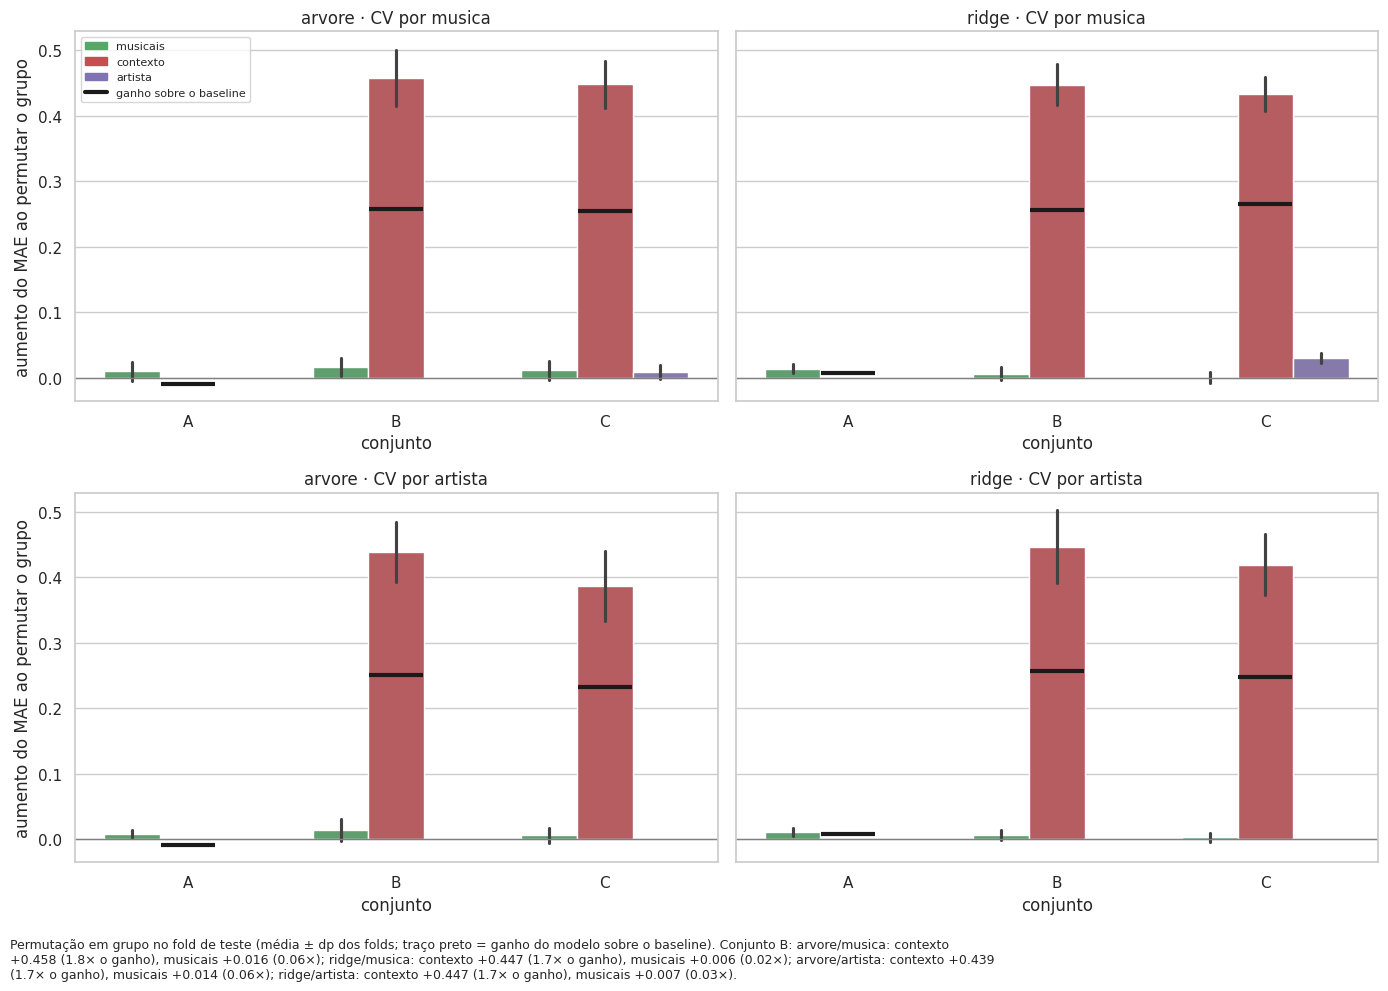

fig_perm_groups.png -> Permutação em grupo no fold de teste (média ± dp dos folds; traço preto = ganho do modelo sobre o baseline). Conjunto B: arvore/musica: contexto +0.458 (1.8× o ganho), musicais +0.016 (0.06×); ridge/musica: contexto +0.447 (1.7× o ganho), musicais +0.006 (0.02×); arvore/artista: contexto +0.439 (1.7× o ganho), musicais +0.014 (0.06×); ridge/artista: contexto +0.447 (1.7× o ganho), musicais +0.007 (0.03×).


In [7]:
def group_permutation(pipe, X, y_true, cols, n_repeats, rng):
    """Aumento médio do MAE ao aplicar a mesma permutação de linhas a todas as colunas do grupo."""
    base = mean_absolute_error(y_true, pipe.predict(X))
    out = []
    for _ in range(n_repeats):
        perm, Xp = rng.permutation(len(X)), X.copy()
        for col in cols:                      # coluna a coluna, para manter os dtypes
            Xp[col] = X[col].to_numpy()[perm]
        out.append(mean_absolute_error(y_true, pipe.predict(Xp)) - base)
    return np.mean(out)

rng = np.random.default_rng(SEED)
rows = []
for (sc, r, k, m, c), pipe in FITTED.items():
    te = TEST_IDX[(sc, r, k)]
    X = d.iloc[te][FEATURES[c]]
    for gname, cols in GRUPOS.items():
        cols = [col for col in cols if col in FEATURES[c]]
        if cols:
            rows.append(dict(cenario=sc, rep=r, fold=k, modelo=m, conjunto=c, grupo=gname,
                             delta_mae=group_permutation(pipe, X, y[te], cols, N_PERM_REPEATS, rng),
                             ganho_sobre_baseline=base_mae.loc[(sc, r, k)] - mae_fold.loc[(sc, r, k, m, c)]))
pg = pd.DataFrame(rows)
pg_agg = (pg.groupby(["cenario", "modelo", "conjunto", "grupo"])
            .agg(delta_mae=("delta_mae", "mean"), dp=("delta_mae", "std"), ganho_sobre_baseline=("ganho_sobre_baseline", "mean"))
            .reset_index())
# a razão só faz sentido quando há ganho (no conjunto A ele é ~0)
pg_agg["razao_ganho"] = np.where(pg_agg.ganho_sobre_baseline > 0.02, pg_agg.delta_mae / pg_agg.ganho_sobre_baseline, np.nan)
pg_agg.to_csv(TABLES_DIR / "tab_perm_groups.csv", index=False)
display(pg_agg.round(3))

fig, ax = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
for i, sc in enumerate(SCENARIOS):
    for j, m in enumerate(MODEL_NAMES):
        a, s = ax[i, j], pg[(pg.cenario == sc) & (pg.modelo == m)]
        sns.barplot(data=s, x="conjunto", y="delta_mae", hue="grupo", order=list(FEATURES), hue_order=list(GRUPOS),
                    palette=GROUP_COLORS, errorbar="sd", ax=a)
        gain = s.groupby("conjunto")["ganho_sobre_baseline"].mean().reindex(list(FEATURES))
        a.scatter(range(len(gain)), gain, marker="_", s=1500, linewidths=3, color="k", zorder=4)
        a.axhline(0, color="gray", lw=1); a.set_title(f"{m} · CV por {sc}"); a.set_xlabel("conjunto")
        a.set_ylabel("aumento do MAE ao permutar o grupo" if j == 0 else "")
        if a.get_legend() is not None:
            a.get_legend().remove()
ax[0, 0].legend(handles=[Patch(color=GROUP_COLORS[gname], label=gname) for gname in GRUPOS] +
                [Line2D([0], [0], color="k", lw=3, label="ganho sobre o baseline")], fontsize=8, loc="upper left")
gB = pg_agg[pg_agg.conjunto == "B"].set_index(["cenario", "modelo", "grupo"])
save_fig(fig, "fig_perm_groups.png",
         "Permutação em grupo no fold de teste (média ± dp dos folds; traço preto = ganho do modelo sobre o baseline). Conjunto B: " +
         "; ".join(f"{m}/{sc}: contexto +{gB.loc[(sc, m, 'contexto'), 'delta_mae']:.3f} "
                   f"({gB.loc[(sc, m, 'contexto'), 'razao_ganho']:.1f}× o ganho), musicais +{gB.loc[(sc, m, 'musicais'), 'delta_mae']:.3f} "
                   f"({gB.loc[(sc, m, 'musicais'), 'razao_ganho']:.2f}×)"
                   for sc in SCENARIOS for m in MODEL_NAMES) + ".")

## 3. SHAP

O valor de Shapley de um atributo é a sua contribuição média para a previsão, considerando todas as ordens em que os atributos poderiam "entrar" no modelo. O SHAP aplica essa ideia a cada música e decompõe a previsão de forma **aditiva**:

$$f(x) = \mathbb{E}[f(X)] + \sum_j \varphi_j(x),$$

em que $\mathbb{E}[f(X)]$ (o valor base) é a previsão média no fundo, que aqui são os dados de treino, e $\varphi_j$ é a contribuição do atributo $j$, em `log1p(streams)`.

- **Árvore:** `TreeExplainer` intervencional, exato para árvores. Há dois cuidados técnicos:
  - Se a matriz de fundo for passada direto em `data`, o shap usa só 100 linhas sorteadas. Por isso o fundo vai num `maskers.Independent` com `max_samples` igual ao tamanho do treino.
  - O TreeSHAP intervencional do shap guarda os limiares em float32, enquanto o sklearn compara `float32(x) <= limiar` com o limiar em float64. Quando uma música de teste tem um valor que não aparece no treino do fold (ex.: 61 entre 60 e 62), o limiar cai exatamente sobre ela, e os dois podem mandá-la para lados diferentes. A soma dos SHAP deixa então de bater com a previsão. A solução é explicar uma cópia da árvore com os limiares arredondados para baixo até o float32 representável: para entradas float32 a decisão é idêntica, e o notebook confere que as previsões não mudam.
- **Ridge:** `LinearExplainer`, que tem solução fechada $\varphi_j = \beta_j\,(x_j - \bar{x}_j)$. O notebook confere essa igualdade.
- **One-hot:** os SHAP das dummies de um mesmo atributo são somados. Para a Ridge, que é aditiva, isso é exato. Para a árvore é uma aproximação, medida em 3.1.
- **Quais modelos:** os modelos **finais** B nas 952 músicas mostram o que o modelo aprendeu e são a base dos gráficos. Os 30 modelos B de fold de cada tipo são explicados no próprio fold de teste, com o treino do fold como fundo, e servem para medir a estabilidade (3.3).
- A versão intervencional trata os atributos como independentes ao montar as coalizões. Com as correlações moderadas desta base (VIF ≤ 1,8 no notebook 02), isso é razoável, mas não elimina combinações irreais.

In [8]:
def group_matrix(info, feats):
    """Matriz 0/1 (colunas transformadas x atributos originais) que soma as dummies de cada atributo."""
    G = np.zeros((len(info), len(feats)))
    for j, i in enumerate(info):
        G[j, feats.index(i["feature"])] = 1.0
    return G

def float32_safe(tree, *Xs):
    """Cópia da árvore com limiares arredondados para baixo em float32 (o TreeSHAP do shap compara em float32).
    Para x em float32 (o sklearn sempre converte), x <= limiar64 equivale a x <= limiar32 arredondado para baixo."""
    t = copy.deepcopy(tree)
    st = t.tree_.__getstate__()
    thr = st["nodes"]["threshold"]; t32 = thr.astype(np.float32)
    st["nodes"]["threshold"] = np.where(t32.astype(np.float64) > thr, np.nextafter(t32, np.float32(-np.inf)), t32).astype(np.float64)
    t.tree_.__setstate__(st)
    assert all(np.array_equal(t.predict(X), tree.predict(X)) for X in Xs), "arredondamento mudou alguma previsão"
    return t

def shap_original(pipe, X_expl, X_bg, feats):
    """SHAP por atributo original: (DataFrame n x atributos, valor base)."""
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    Xe, Xb = to_dense(prep.transform(X_expl)), to_dense(prep.transform(X_bg))
    masker = shap.maskers.Independent(Xb, max_samples=len(Xb))     # fundo completo, sem sorteio de 100 linhas
    if isinstance(model, DecisionTreeRegressor):
        ex = shap.TreeExplainer(float32_safe(model, Xe, Xb), data=masker, feature_perturbation="interventional")
    else:
        ex = shap.LinearExplainer(model, masker)
    sv = ex.shap_values(Xe)
    if not isinstance(model, DecisionTreeRegressor):
        assert np.allclose(sv, (Xe - Xb.mean(0)) * model.coef_), "LinearExplainer difere de beta * (x - média)"
    base = float(np.ravel(ex.expected_value)[0])
    phi = sv @ group_matrix(split_info(prep), feats)
    assert np.allclose(base + phi.sum(1), pipe.predict(X_expl), atol=1e-5), "SHAP não soma a previsão"
    return pd.DataFrame(phi, columns=feats, index=X_expl.index), base

# Modelos finais: 952 músicas, fundo = treino completo
SHAP_FINAL, BASE_FINAL = {}, {}
for m, pipe in FINAL.items():
    SHAP_FINAL[m], BASE_FINAL[m] = shap_original(pipe, d[FB], d[FB], FB)
pd.concat([v.assign(modelo=m, row_id=d["row_id"].to_numpy(), base=BASE_FINAL[m]) for m, v in SHAP_FINAL.items()]
          ).to_csv(TABLES_DIR / "shap_values_final.csv", index=False)
print("Valor base (previsão média no treino): " +
      "; ".join(f"{m} = {b:.3f} (≈ {milhoes(b):.0f} M de streams)" for m, b in BASE_FINAL.items()))

# Modelos de fold (conjunto B): fold de teste, fundo = treino do fold
rows = []
for (sc, r, k, m, c), pipe in FITTED.items():
    if c == "B":
        phi, _ = shap_original(pipe, d.iloc[TEST_IDX[(sc, r, k)]][FB], d.iloc[TRAIN_IDX[(sc, r, k)]][FB], FB)
        rows += [dict(cenario=sc, rep=r, fold=k, modelo=m, feature=f, mean_abs_shap=v) for f, v in phi.abs().mean().items()]
shap_folds = pd.DataFrame(rows)
shap_folds.to_csv(TABLES_DIR / "tab_shap_folds.csv", index=False)
print(f"SHAP dos modelos de fold: {shap_folds.groupby(['cenario', 'rep', 'fold', 'modelo']).ngroups} modelos (conjunto B)")

# Códigos das categóricas, só para colorir o beeswarm (período em ordem cronológica)
CODES = {"release_period": PERIODS, "mode": ["Minor", "Major"],
         "key": sorted(k for k in d["key"].unique() if k != "Unknown") + ["Unknown"]}
def as_codes(X):
    Z = X.copy()
    for col, cats in CODES.items():
        if col in Z:
            Z[col] = Z[col].map({c: i for i, c in enumerate(cats)})
    return Z.astype(float)

Valor base (previsão média no treino): arvore = 19.507 (≈ 296 M de streams); ridge = 19.507 (≈ 296 M de streams)


SHAP dos modelos de fold: 60 modelos (conjunto B)


### 3.1 Conferência pela definição de Shapley (árvore final)

Somar os SHAP das dummies trata cada dummy como um "jogador" separado. Na árvore, as dummies de `release_period` interagem entre si e com os atributos musicais, então a soma não é, em geral, igual ao valor de Shapley de `release_period` tratado como **um único** jogador.

Para medir essa diferença, o Shapley é calculado pela definição, com os atributos originais como jogadores:

$$\varphi_j(x) = \sum_{S \subseteq N \setminus \{j\}} \frac{|S|!\,(k-|S|-1)!}{k!}\,\big[v(S \cup \{j\}) - v(S)\big], \qquad v(S) = \text{média no fundo de } f(x_S,\ \text{fundo}_{N \setminus S}).$$

Entram como jogadores só os atributos que a árvore usa. Os demais têm $\varphi = 0$, porque não mudam a previsão. A comparação usa `N_EXACT` músicas e `N_EXACT_BG` linhas de fundo, sorteadas com a semente, e o mesmo fundo no TreeSHAP.

In [9]:
def shapley_exato(pipe, X, bg, players):
    """Shapley intervencional exato, por enumeração de todas as coalizões de `players` (atributos originais)."""
    n, nb, k = len(X), len(bg), len(players)
    rep_x = X.loc[X.index.repeat(nb)].reset_index(drop=True)   # cada música repetida nb vezes
    rep_bg = pd.concat([bg] * n, ignore_index=True)             # o fundo empilhado n vezes
    v = {}
    for size in range(k + 1):
        for S in combinations(players, size):
            Z = rep_bg.copy()
            for col in S:
                Z[col] = rep_x[col].to_numpy()
            v[S] = pipe.predict(Z).reshape(n, nb).mean(axis=1)  # v(S) de cada música
    phi = pd.DataFrame(0.0, index=X.index, columns=players)
    for j in players:
        others = [p for p in players if p != j]
        for size in range(k):
            w = factorial(size) * factorial(k - size - 1) / factorial(k)
            for S in combinations(others, size):
                phi[j] += w * (v[tuple(p for p in players if p in S or p == j)] - v[S])
    return phi, v[()][0]

rs = np.random.default_rng(SEED)
Xs = d.iloc[rs.choice(len(d), N_EXACT, replace=False)][FB]
Bs = d.iloc[rs.choice(len(d), N_EXACT_BG, replace=False)][FB]
info_t = split_info(tree_final.named_steps["prep"])
used = {info_t[j]["feature"] for j in tm_final.tree_.feature if j >= 0}
players = [f for f in FB if f in used]
phi_ex, v_vazio = shapley_exato(tree_final, Xs, Bs, players)
assert np.allclose(v_vazio + phi_ex.sum(1), tree_final.predict(Xs)), "eficiência violada: Σφ deveria ser f(x) − v(∅)"
phi_ts, base_ts = shap_original(tree_final, Xs, Bs, FB)
assert np.isclose(base_ts, v_vazio, atol=1e-6) and np.abs(phi_ts.drop(columns=players).to_numpy()).max() < 1e-9

dif = (phi_ex - phi_ts[players]).abs()
comp = pd.DataFrame({"media_abs_exato": phi_ex.abs().mean(), "media_abs_treeshap_somado": phi_ts[players].abs().mean(),
                     "dif_media": dif.mean(), "dif_max": dif.max(),
                     "correlacao": [np.corrcoef(phi_ex[p], phi_ts[p])[0, 1] for p in players]}).rename_axis("feature")
comp.to_csv(TABLES_DIR / "tab_shap_exact_check.csv")
display(comp.round(4))
rank_ok = comp["media_abs_exato"].rank().equals(comp["media_abs_treeshap_somado"].rank())
print(f"Jogadores ({len(players)}, {2 ** len(players)} coalizões): {players}. Mesmo ranking global: {rank_ok}. "
      f"Maior diferença individual: {dif.to_numpy().max():.3f} em log1p (≈ ×{np.exp(dif.to_numpy().max()):.2f} nos streams previstos).")

,media_abs_exato,media_abs_treeshap_somado,dif_media,dif_max,correlacao
feature,,,,,
danceability_%,0.0685,0.0660,0.0025,0.0175,0.9998
valence_%,0.0366,0.0366,0.0000,0.0000,1.0000
energy_%,0.0121,0.0121,0.0000,0.0000,1.0000
liveness_%,0.0148,0.0148,0.0000,0.0000,1.0000
release_period,0.6857,0.6847,0.0025,0.0175,1.0000


Jogadores (5, 32 coalizões): ['danceability_%', 'valence_%', 'energy_%', 'liveness_%', 'release_period']. Mesmo ranking global: True. Maior diferença individual: 0.017 em log1p (≈ ×1.02 nos streams previstos).


### 3.2 Explicação global

- **Barras:** média de |φ| por atributo no modelo final, ou seja, quanto cada atributo desloca a previsão, em média. A linha preta vai do mínimo ao máximo entre os 15 modelos de fold do cenário por música, cada um explicado no seu fold de teste.
- **Beeswarm:** cada ponto é uma música; a posição é φ e a cor é o valor do atributo. Nas categóricas, a cor usa códigos: `release_period` em ordem cronológica (azul = antigo, vermelho = recente) e `mode` com Minor = 0 e Major = 1. Em `key` a ordem das notas é arbitrária, então a cor não tem significado.
- **Fração musical:** a parte da atribuição total (soma das médias de |φ|) que vem dos 10 atributos musicais.

,arvore,ridge,arvore_folds_min,arvore_folds_max,ridge_folds_min,ridge_folds_max,grupo
feature,,,,,,,
bpm,0.0000,0.0282,0.0000,0.0296,0.0118,0.0447,musicais
key,0.0000,0.0440,0.0000,0.0000,0.0373,0.0799,musicais
mode,0.0000,0.0144,0.0000,0.0000,0.0000,0.0582,musicais
danceability_%,0.0662,0.0732,0.0000,0.0860,0.0333,0.0996,musicais
valence_%,0.0378,0.0211,0.0000,0.0465,0.0077,0.0522,musicais
energy_%,0.0177,0.0024,0.0000,0.0256,0.0002,0.0321,musicais
acousticness_%,0.0000,0.0211,0.0000,0.0470,0.0005,0.0588,musicais
instrumentalness_%,0.0000,0.0231,0.0000,0.0000,0.0137,0.0372,musicais
liveness_%,0.0167,0.0032,0.0000,0.0335,0.0001,0.0169,musicais


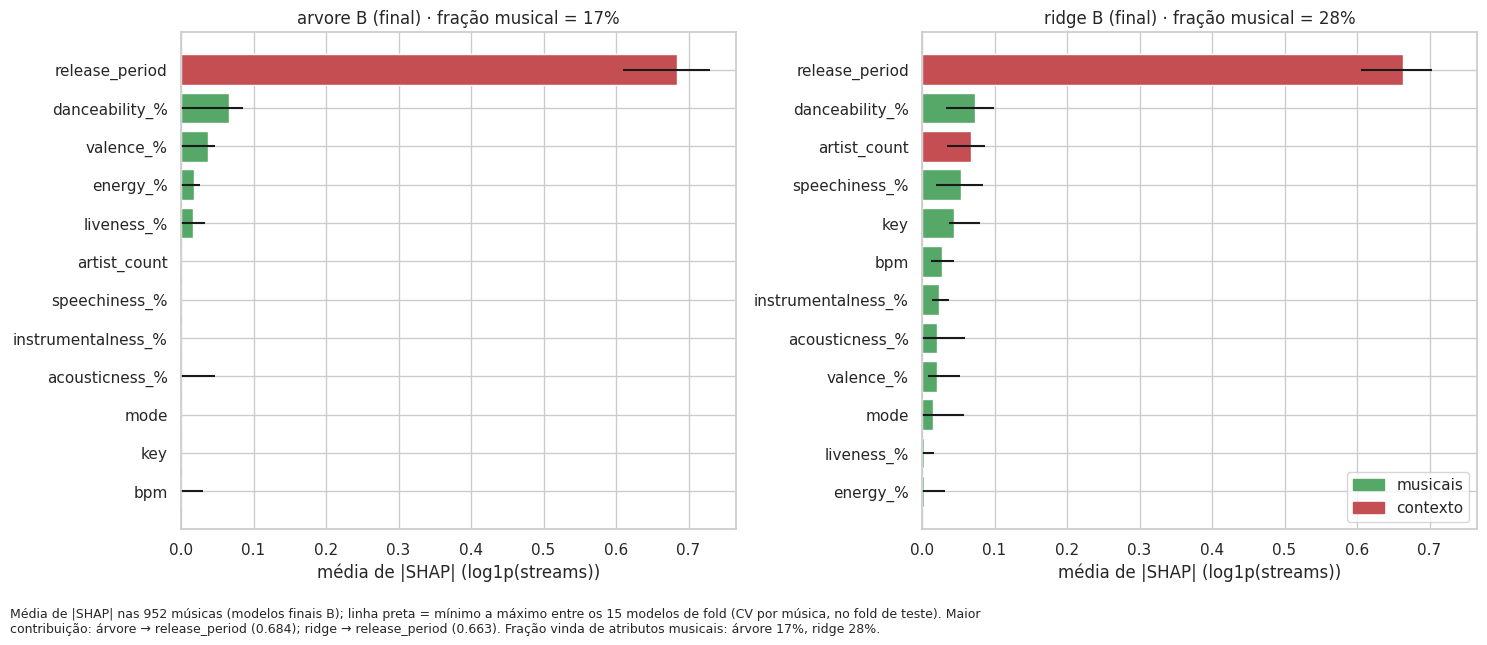

fig_shap_bar.png -> Média de |SHAP| nas 952 músicas (modelos finais B); linha preta = mínimo a máximo entre os 15 modelos de fold (CV por música, no fold de teste). Maior contribuição: árvore → release_period (0.684); ridge → release_period (0.663). Fração vinda de atributos musicais: árvore 17%, ridge 28%.


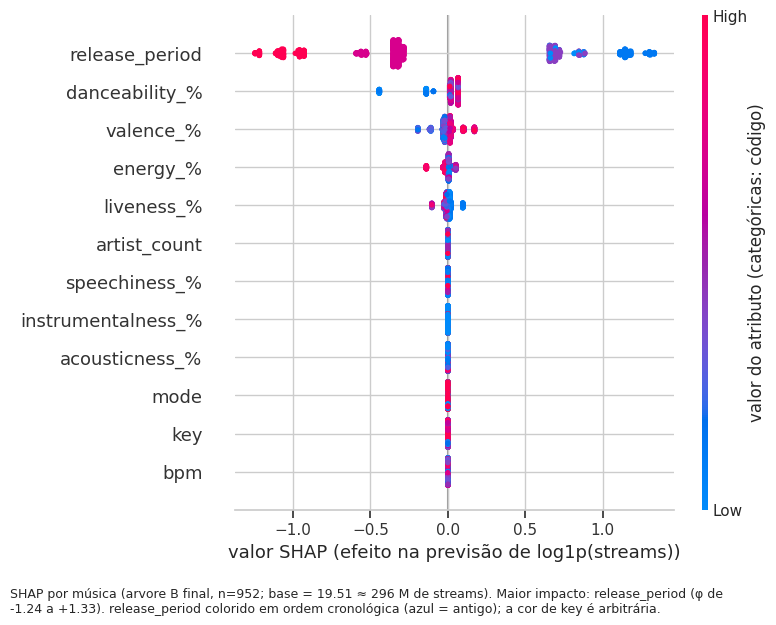

fig_shap_beeswarm_arvore.png -> SHAP por música (arvore B final, n=952; base = 19.51 ≈ 296 M de streams). Maior impacto: release_period (φ de -1.24 a +1.33). release_period colorido em ordem cronológica (azul = antigo); a cor de key é arbitrária.


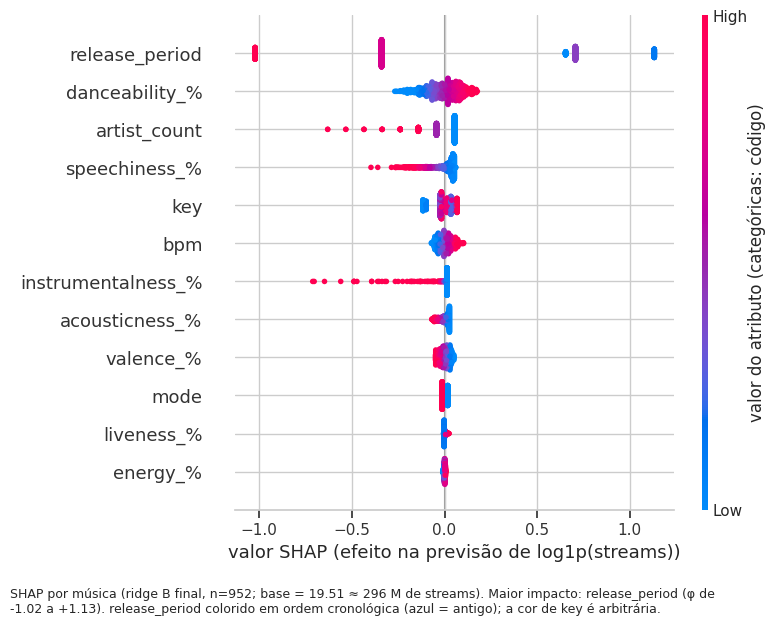

fig_shap_beeswarm_ridge.png -> SHAP por música (ridge B final, n=952; base = 19.51 ≈ 296 M de streams). Maior impacto: release_period (φ de -1.02 a +1.13). release_period colorido em ordem cronológica (azul = antigo); a cor de key é arbitrária.


In [10]:
sg = pd.DataFrame({m: v.abs().mean() for m, v in SHAP_FINAL.items()}).rename_axis("feature")
fm = shap_folds[shap_folds.cenario == "musica"].groupby(["modelo", "feature"])["mean_abs_shap"]
for m in SHAP_FINAL:
    sg[f"{m}_folds_min"] = fm.min().loc[m].reindex(sg.index)
    sg[f"{m}_folds_max"] = fm.max().loc[m].reindex(sg.index)
sg["grupo"] = np.where(sg.index.isin(MUSICAIS), "musicais", "contexto")
share_final = {m: sg.loc[sg.grupo == "musicais", m].sum() / sg[m].sum() for m in SHAP_FINAL}
sg.to_csv(TABLES_DIR / "tab_shap_global.csv")
display(sg.round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for a, m in zip(ax, MODEL_NAMES):
    s = sg.sort_values(m)
    a.barh(s.index, s[m], color=[GROUP_COLORS[x] for x in s.grupo])
    a.hlines(range(len(s)), s[f"{m}_folds_min"], s[f"{m}_folds_max"], color="k", lw=1.5)
    a.set_title(f"{m} B (final) · fração musical = {100 * share_final[m]:.0f}%"); a.set_xlabel("média de |SHAP| (log1p(streams))")
ax[1].legend(handles=[Patch(color=GROUP_COLORS[gname], label=gname) for gname in ["musicais", "contexto"]], loc="lower right")
top_t, top_r = sg["arvore"].idxmax(), sg["ridge"].idxmax()
save_fig(fig, "fig_shap_bar.png",
         f"Média de |SHAP| nas {len(d)} músicas (modelos finais B); linha preta = mínimo a máximo entre os 15 modelos de fold (CV por música, "
         f"no fold de teste). Maior contribuição: árvore → {top_t} ({sg.loc[top_t, 'arvore']:.3f}); ridge → {top_r} "
         f"({sg.loc[top_r, 'ridge']:.3f}). Fração vinda de atributos musicais: árvore {100 * share_final['arvore']:.0f}%, "
         f"ridge {100 * share_final['ridge']:.0f}%.")

for m in MODEL_NAMES:
    expl = shap.Explanation(values=SHAP_FINAL[m].to_numpy(), base_values=np.full(len(d), BASE_FINAL[m]),
                            data=as_codes(d[FB]).to_numpy(), feature_names=FB)
    plt.figure()
    ax_b = shap.plots.beeswarm(expl, max_display=len(FB), show=False, color_bar_label="valor do atributo (categóricas: código)")
    ax_b.set_xlabel("valor SHAP (efeito na previsão de log1p(streams))")
    f_top = SHAP_FINAL[m].abs().mean().idxmax()
    save_fig(plt.gcf(), f"fig_shap_beeswarm_{m}.png",
             f"SHAP por música ({m} B final, n={len(d)}; base = {BASE_FINAL[m]:.2f} ≈ {milhoes(BASE_FINAL[m]):.0f} M de streams). "
             f"Maior impacto: {f_top} (φ de {SHAP_FINAL[m][f_top].min():+.2f} a {SHAP_FINAL[m][f_top].max():+.2f}). "
             "release_period colorido em ordem cronológica (azul = antigo); a cor de key é arbitrária.")

### 3.3 Estabilidade entre folds e concordância entre métodos

- **Estabilidade:** em cada um dos 15 modelos de fold de um cenário, os atributos são ordenados pela média de |φ| no fold de teste. Reporta-se o Spearman médio entre os rankings de pares de folds e em quantos folds cada atributo fica entre os 3 primeiros.
- **Fração musical por fold:** a mesma medida da seção 3.2, calculada em cada fold.
- **Concordância entre métodos:** Spearman entre a média de |φ| e o aumento médio de MAE da permutação (seção 2), por modelo e cenário. **Entre modelos:** Spearman entre a média de |φ| da árvore e a da Ridge.

Concordância alta entre métodos e modelos indica que o padrão vem dos dados, dentro desta amostra, e não de um método específico.

**SHAP e permutação medem coisas diferentes.** O SHAP mede quanto um atributo **move** a previsão; a permutação mede quanto ele **reduz o erro** em músicas não vistas. Um atributo pode mover a previsão sem reduzir o erro (efeitos pequenos ajustados a ruído), e então a fração musical do SHAP fica bem maior que a contribuição musical medida pela permutação.

,cenario,modelo,spearman_ranking_folds,fracao_musical_media,fracao_musical_dp,concordancia_shap_perm,top1_mais_frequente,pct_folds_top1,concordancia_arvore_ridge
0,artista,arvore,0.662,15.021,3.790,0.631,release_period,100.0,0.239
1,artista,ridge,0.792,30.129,3.096,0.594,release_period,100.0,0.239
2,musica,arvore,0.703,13.397,4.206,0.609,release_period,100.0,0.167
3,musica,ridge,0.780,29.931,2.501,0.622,release_period,100.0,0.167


% dos folds em que o atributo fica entre os 3 de maior média |SHAP|:


cenario            artista        musica       
modelo              arvore  ridge arvore  ridge
bpm                    0.0    0.0   20.0    0.0
key                    0.0   27.0   13.0   27.0
mode                   0.0    0.0   13.0    0.0
danceability_%        73.0   80.0   93.0   73.0
valence_%             87.0    0.0   80.0    0.0
energy_%              13.0    0.0   13.0    0.0
acousticness_%        13.0    0.0   20.0    7.0
instrumentalness_%     0.0    0.0   13.0    0.0
liveness_%             0.0    0.0   27.0    0.0
speechiness_%         13.0   20.0   13.0   27.0
release_period       100.0  100.0  100.0  100.0
artist_count           0.0   73.0   13.0   67.0

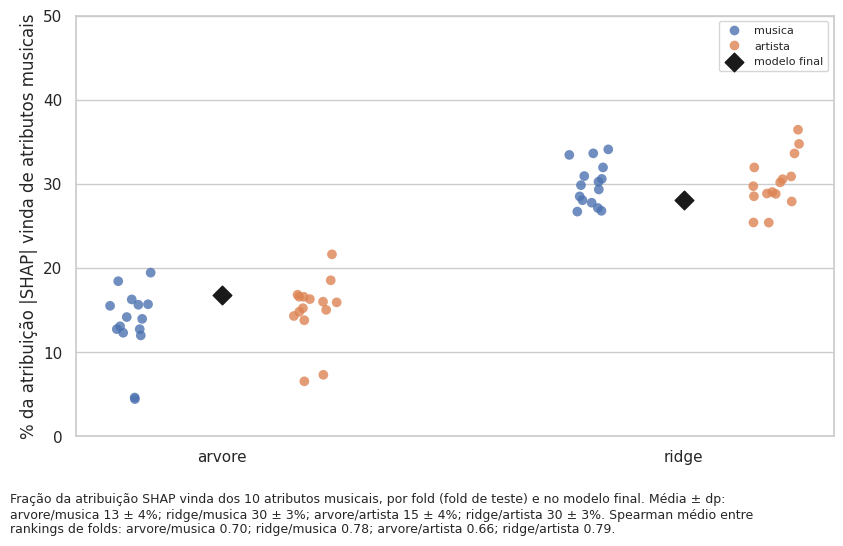

fig_shap_share.png -> Fração da atribuição SHAP vinda dos 10 atributos musicais, por fold (fold de teste) e no modelo final. Média ± dp: arvore/musica 13 ± 4%; ridge/musica 30 ± 3%; arvore/artista 15 ± 4%; ridge/artista 30 ± 3%. Spearman médio entre rankings de folds: arvore/musica 0.70; ridge/musica 0.78; arvore/artista 0.66; ridge/artista 0.79.


In [11]:
def pairwise_spearman(M):
    """Spearman entre linhas (folds) de M, só os pares distintos."""
    R = stats.spearmanr(M, axis=1)[0]
    return R[np.triu_indices_from(R, 1)]

rows = []
for (sc, m), g in shap_folds.groupby(["cenario", "modelo"]):
    W = g.pivot_table(index=["rep", "fold"], columns="feature", values="mean_abs_shap")[FB]
    share = W[MUSICAIS].sum(1) / W.sum(1)
    perm = pi_agg[(pi_agg.cenario == sc) & (pi_agg.modelo == m) & (pi_agg.conjunto == "B")].set_index("feature")["media"].reindex(FB)
    top1 = W.idxmax(axis=1).value_counts(normalize=True)
    top3 = 100 * (W.rank(axis=1, ascending=False, method="min") <= 3).mean()
    rows.append(dict(cenario=sc, modelo=m, spearman_ranking_folds=np.nanmean(pairwise_spearman(W.to_numpy())),
                     fracao_musical_media=100 * share.mean(), fracao_musical_dp=100 * share.std(),
                     concordancia_shap_perm=stats.spearmanr(W.mean(), perm)[0],
                     top1_mais_frequente=top1.idxmax(), pct_folds_top1=100 * top1.max(), **{f"top3_{f}": top3[f] for f in FB}))
stab_shap = pd.DataFrame(rows)
models_conc = {sc: stats.spearmanr(*[shap_folds[(shap_folds.cenario == sc) & (shap_folds.modelo == m)]
                                     .groupby("feature")["mean_abs_shap"].mean().reindex(FB) for m in MODEL_NAMES])[0]
               for sc in SCENARIOS}
stab_shap["concordancia_arvore_ridge"] = stab_shap.cenario.map(models_conc)
stab_shap.to_csv(TABLES_DIR / "tab_shap_stability.csv", index=False)
display(stab_shap.drop(columns=[c for c in stab_shap if c.startswith("top3_")]).round(3))
print("% dos folds em que o atributo fica entre os 3 de maior média |SHAP|:")
display(stab_shap.set_index(["cenario", "modelo"])[[f"top3_{f}" for f in FB]].T.rename(index=lambda s: s[5:]).round(0))

sh = (shap_folds.assign(musical=shap_folds.feature.isin(MUSICAIS))
      .groupby(["cenario", "modelo", "rep", "fold", "musical"])["mean_abs_shap"].sum().unstack("musical"))
sh = (100 * sh[True] / sh.sum(axis=1)).rename("fracao_musical").reset_index()
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.stripplot(data=sh, x="modelo", y="fracao_musical", hue="cenario", order=MODEL_NAMES, hue_order=SCENARIOS,
              palette=SC_COLORS, dodge=True, size=7, alpha=.8, ax=ax)
ax.scatter(range(len(MODEL_NAMES)), [100 * share_final[m] for m in MODEL_NAMES], marker="D", s=90, color="k", zorder=4,
           label="modelo final")
ax.set_ylim(0, max(50, sh.fracao_musical.max() + 5)); ax.set_xlabel("")
ax.set_ylabel("% da atribuição |SHAP| vinda de atributos musicais"); ax.legend(fontsize=8)
st = stab_shap.set_index(["cenario", "modelo"])
save_fig(fig, "fig_shap_share.png",
         "Fração da atribuição SHAP vinda dos 10 atributos musicais, por fold (fold de teste) e no modelo final. Média ± dp: " +
         "; ".join(f"{m}/{sc} {st.loc[(sc, m), 'fracao_musical_media']:.0f} ± {st.loc[(sc, m), 'fracao_musical_dp']:.0f}%"
                   for sc in SCENARIOS for m in MODEL_NAMES) +
         ". Spearman médio entre rankings de folds: " +
         "; ".join(f"{m}/{sc} {st.loc[(sc, m), 'spearman_ranking_folds']:.2f}" for sc in SCENARIOS for m in MODEL_NAMES) + ".")

### 3.4 Dependência: como a contribuição muda com o valor do atributo

Os gráficos mostram φ contra o valor do atributo para os 3 atributos musicais numéricos com maior média de |φ| (somando os dois modelos finais), com a cor indicando o período de lançamento. Na Ridge a relação é uma reta por construção; na árvore, aparece em degraus nos limiares das regras. A cor mostra se a contribuição depende do período, o que seria uma interação aprendida pela árvore. Para ter referência, a legenda informa a amplitude de φ de `release_period`.

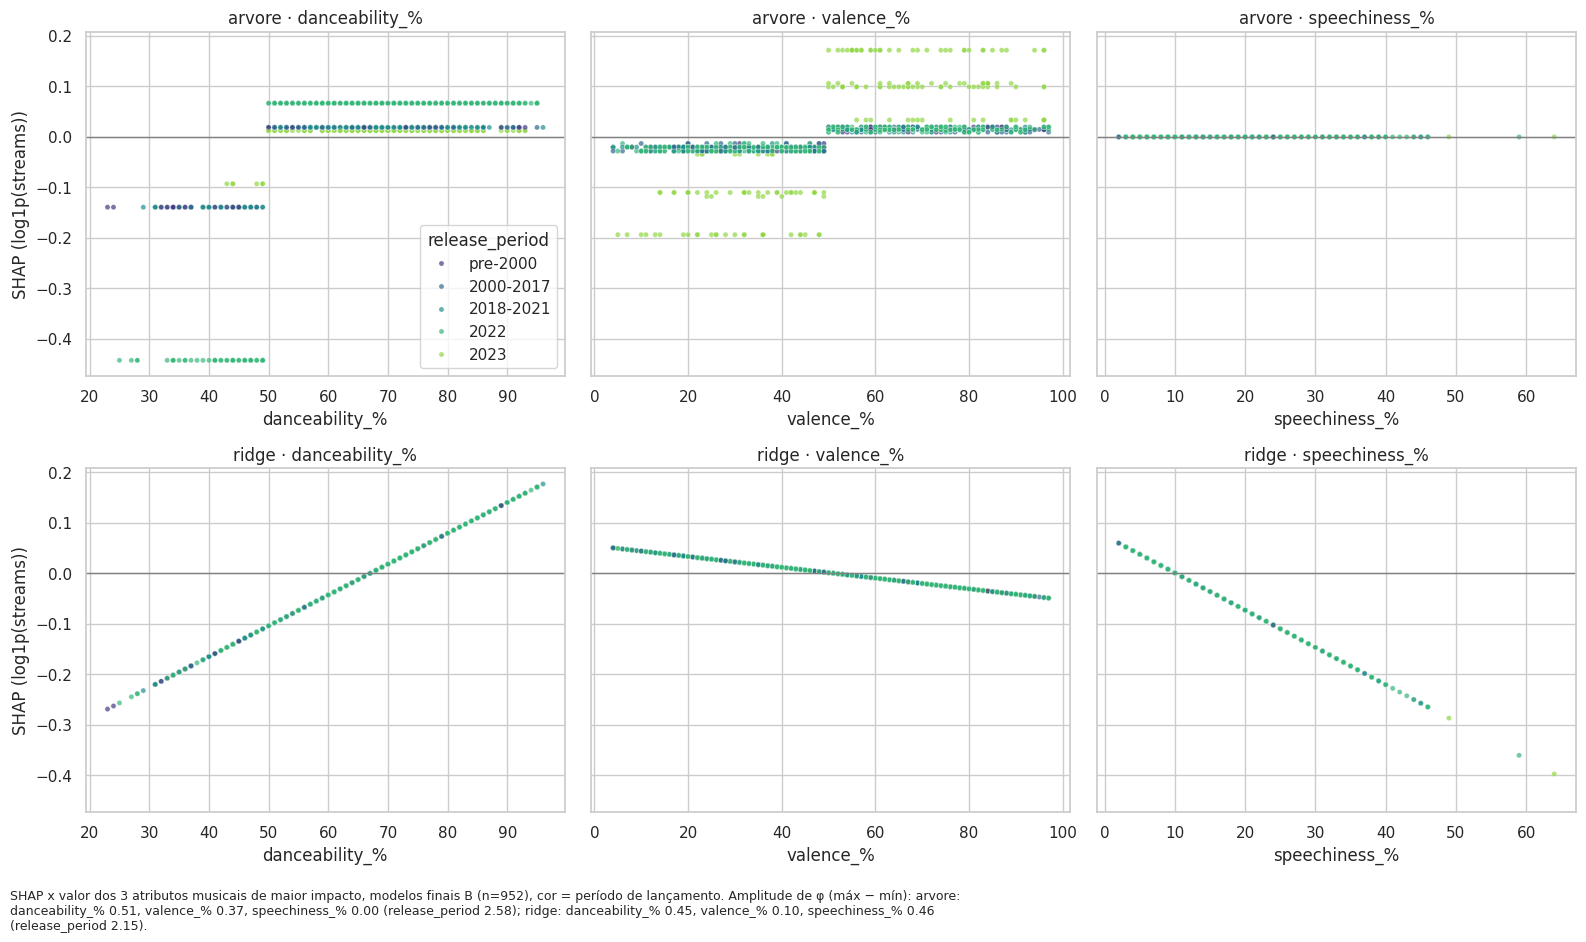

fig_shap_dependence.png -> SHAP x valor dos 3 atributos musicais de maior impacto, modelos finais B (n=952), cor = período de lançamento. Amplitude de φ (máx − mín): arvore: danceability_% 0.51, valence_% 0.37, speechiness_% 0.00 (release_period 2.58); ridge: danceability_% 0.45, valence_% 0.10, speechiness_% 0.46 (release_period 2.15).


In [12]:
num_mus = [f for f in MUSICAIS if f in NUMERIC]
top_feats = sum(SHAP_FINAL[m][num_mus].abs().mean() for m in MODEL_NAMES).sort_values(ascending=False).index[:3].tolist()
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5), sharey=True)
for i, m in enumerate(MODEL_NAMES):
    for j, f in enumerate(top_feats):
        a = ax[i, j]
        sns.scatterplot(x=d[f], y=SHAP_FINAL[m][f], hue=d["release_period"], hue_order=PERIODS, palette="viridis",
                        s=14, alpha=.7, ax=a, legend=(i, j) == (0, 0))
        a.axhline(0, color="gray", lw=1); a.set_title(f"{m} · {f}"); a.set_ylabel("SHAP (log1p(streams))" if j == 0 else "")
amp = {(m, f): np.ptp(SHAP_FINAL[m][f].to_numpy()) for m in MODEL_NAMES for f in top_feats + ["release_period"]}
save_fig(fig, "fig_shap_dependence.png",
         f"SHAP x valor dos 3 atributos musicais de maior impacto, modelos finais B (n={len(d)}), cor = período de lançamento. "
         "Amplitude de φ (máx − mín): " +
         "; ".join(f"{m}: " + ", ".join(f"{f} {amp[(m, f)]:.2f}" for f in top_feats) + f" (release_period {amp[(m, 'release_period')]:.2f})"
                   for m in MODEL_NAMES) + ".")

### 3.5 Explicações individuais

Três músicas escolhidas por regras fixas, e não a dedo:
1. a de **maior número de streams** da base;
2. a **típica**, com streams mais próximo da mediana;
3. a de **maior erro fora da amostra**: maior |log1p(streams) − previsão| da árvore B no cenário por música, repetição 0 (`predictions.csv`), ou seja, de um modelo que não viu a música.

Os waterfalls explicam a **árvore final**. É uma explicação dentro da amostra, coerente com as regras da seção 1. A tabela compara as maiores contribuições da árvore e da Ridge, e $e^{\varphi}$ é o fator multiplicativo aproximado sobre os streams previstos. Se o caso 3 tiver streams implausivelmente baixo, o erro aponta um problema no dado, não no modelo.

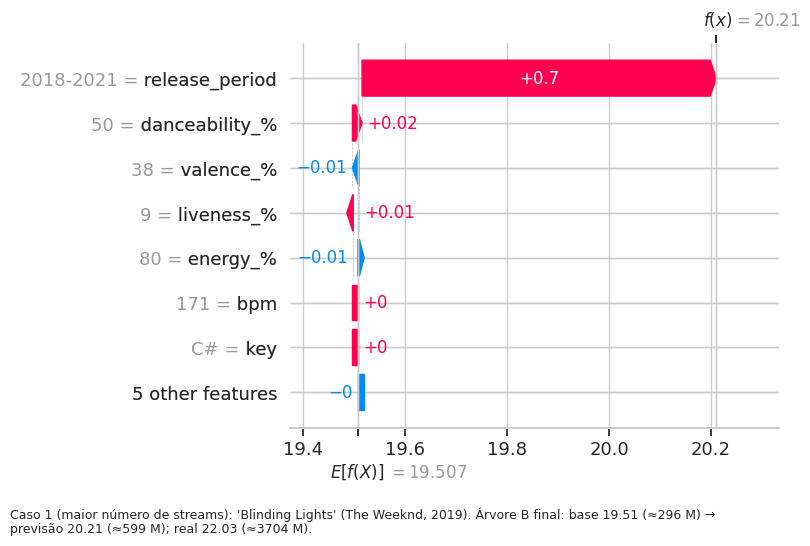

fig_shap_waterfall_1.png -> Caso 1 (maior número de streams): 'Blinding Lights' (The Weeknd, 2019). Árvore B final: base 19.51 (≈296 M) → previsão 20.21 (≈599 M); real 22.03 (≈3704 M).


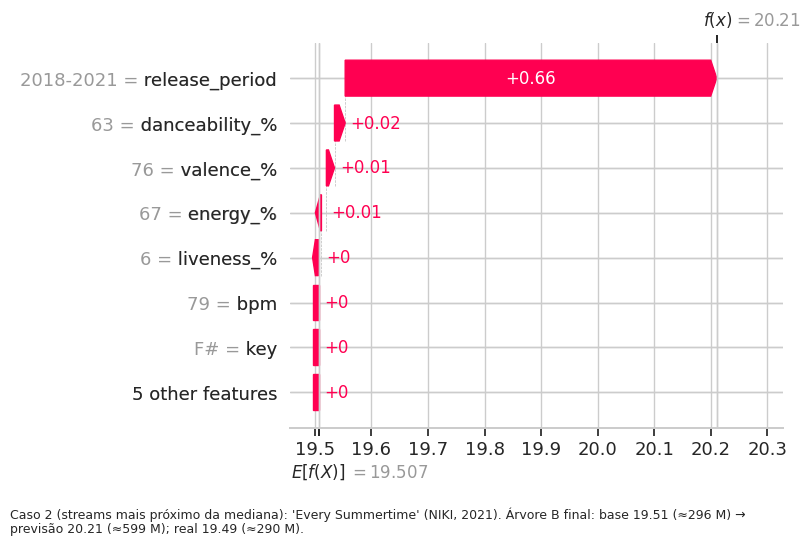

fig_shap_waterfall_2.png -> Caso 2 (streams mais próximo da mediana): 'Every Summertime' (NIKI, 2021). Árvore B final: base 19.51 (≈296 M) → previsão 20.21 (≈599 M); real 19.49 (≈290 M).


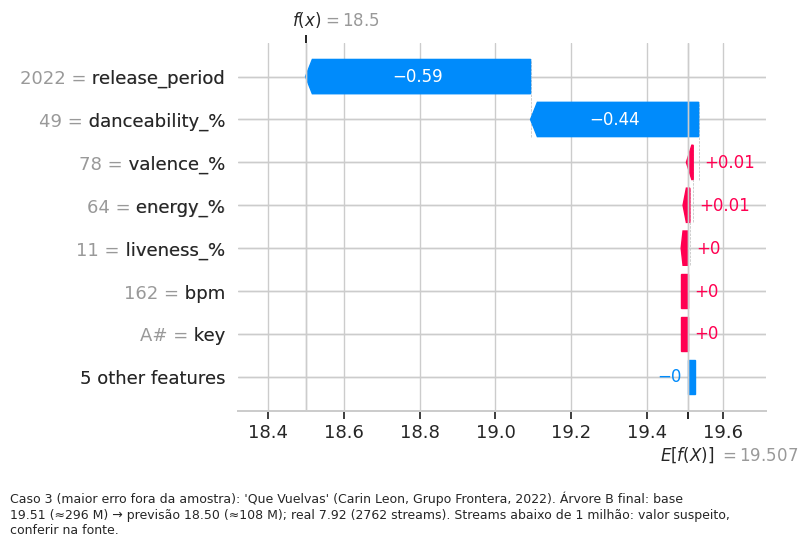

fig_shap_waterfall_3.png -> Caso 3 (maior erro fora da amostra): 'Que Vuelvas' (Carin Leon, Grupo Frontera, 2022). Árvore B final: base 19.51 (≈296 M) → previsão 18.50 (≈108 M); real 7.92 (2762 streams). Streams abaixo de 1 milhão: valor suspeito, conferir na fonte.


,caso,track_name,artistas,ano,streams_M,modelo,base,previsao,previsao_M,previsao_fora_amostra_M,maiores_contribuicoes
0,maior número de streams,Blinding Lights,The Weeknd,2019,3703.90,arvore,19.51,20.21,598.83,612.14,release_period=2018-2021: +0.70 (×2.00); danceability_%=50: +0.02 (×1.02); valence_%=38: -0.01 (×0.99); liveness_%=9...
1,maior número de streams,Blinding Lights,The Weeknd,2019,3703.90,ridge,19.51,20.32,669.12,NaN,release_period=2018-2021: +0.71 (×2.03); danceability_%=50: -0.10 (×0.90); bpm=171: +0.06 (×1.06); artist_count=1: +...
2,streams mais próximo da mediana,Every Summertime,NIKI,2021,290.23,arvore,19.51,20.21,598.83,600.83,release_period=2018-2021: +0.66 (×1.93); danceability_%=63: +0.02 (×1.02); valence_%=76: +0.01 (×1.01); energy_%=67:...
3,streams mais próximo da mediana,Every Summertime,NIKI,2021,290.23,ridge,19.51,20.23,612.82,NaN,release_period=2018-2021: +0.71 (×2.03); artist_count=1: +0.05 (×1.06); bpm=79: -0.05 (×0.95); speechiness_%=4: +0.0...
4,maior erro fora da amostra,Que Vuelvas,"Carin Leon, Grupo Frontera",2022,0.00,arvore,19.51,18.50,108.26,136.57,release_period=2022: -0.59 (×0.55); danceability_%=49: -0.44 (×0.64); valence_%=78: +0.01 (×1.01); energy_%=64: +0.0...
5,maior erro fora da amostra,Que Vuelvas,"Carin Leon, Grupo Frontera",2022,0.00,ridge,19.51,18.99,175.88,NaN,release_period=2022: -0.34 (×0.71); danceability_%=49: -0.11 (×0.90); key=A#: -0.10 (×0.91); bpm=162: +0.05 (×1.05)


In [13]:
oof = saved[(saved.cenario == "musica") & (saved.rep == 0) & (saved.modelo == "arvore") & (saved.conjunto == "B")].set_index("row_id")
oof_err = (oof["y_true"] - oof["y_pred"]).abs()
cases = {"maior número de streams": d[TARGET].idxmax(),
         "streams mais próximo da mediana": (d[TARGET] - d[TARGET].median()).abs().idxmin(),
         "maior erro fora da amostra": pos.loc[oof_err.idxmax()]}
DISPLAY = d[FB].astype(object)
rows = []
for n, (case, i) in enumerate(cases.items(), start=1):
    s = d.loc[i]
    for m in MODEL_NAMES:
        phi = SHAP_FINAL[m].loc[i]
        top = phi.reindex(phi.abs().sort_values(ascending=False).index[:4])
        rows.append(dict(caso=case, track_name=s["track_name"], artistas=s["artist(s)_name"], ano=int(s["released_year"]),
                         streams_M=s["streams"] / 1e6, modelo=m, base=BASE_FINAL[m], previsao=BASE_FINAL[m] + phi.sum(),
                         previsao_M=milhoes(BASE_FINAL[m] + phi.sum()),
                         previsao_fora_amostra_M=milhoes(oof.loc[s["row_id"], "y_pred"]) if m == "arvore" else np.nan,
                         maiores_contribuicoes="; ".join(f"{f}={DISPLAY.loc[i, f]}: {v:+.2f} (×{np.exp(v):.2f})" for f, v in top.items())))
    expl = shap.Explanation(values=SHAP_FINAL["arvore"].loc[i].to_numpy(), base_values=BASE_FINAL["arvore"],
                            data=as_codes(d.loc[[i], FB]).to_numpy()[0], display_data=DISPLAY.loc[i].to_numpy(), feature_names=FB)
    plt.figure()
    shap.plots.waterfall(expl, max_display=8, show=False)
    pred = BASE_FINAL["arvore"] + SHAP_FINAL["arvore"].loc[i].sum()
    aviso = " Streams abaixo de 1 milhão: valor suspeito, conferir na fonte." if s["streams"] < 1e6 else ""
    real_txt = f"{s['streams']:.0f} streams" if s["streams"] < 1e6 else f"≈{s['streams'] / 1e6:.0f} M"
    save_fig(plt.gcf(), f"fig_shap_waterfall_{n}.png",
             f"Caso {n} ({case}): '{s['track_name']}' ({s['artist(s)_name']}, {int(s['released_year'])}). Árvore B final: base "
             f"{BASE_FINAL['arvore']:.2f} (≈{milhoes(BASE_FINAL['arvore']):.0f} M) → previsão {pred:.2f} (≈{milhoes(pred):.0f} M); "
             f"real {s[TARGET]:.2f} ({real_txt}).{aviso}")
ex_tab = pd.DataFrame(rows)
ex_tab.to_csv(TABLES_DIR / "tab_shap_examples.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(ex_tab.round(2))

## 4. Síntese automática (`reports/interpretability_summary.md`) e legendas

In [14]:
gC = pg_agg[pg_agg.conjunto == "C"].set_index(["cenario", "modelo", "grupo"])
gp = cvres[cvres.modelo != "baseline"].merge(base_mae.rename("mae_base").reset_index(), on=["cenario", "rep", "fold"])
g_pct = (100 * (gp.mae_base - gp.mae) / gp.mae_base).groupby([gp.cenario, gp.modelo, gp.conjunto]).mean()   # % de ganho de MAE
n_low = int((d["streams"] < 1e6).sum())
n_moj = int((d["track_name"].str.contains("ï¿½|�", na=False) | d["artist(s)_name"].str.contains("ï¿½|�", na=False)).sum())
both = [(sc, m) for sc in SCENARIOS for m in MODEL_NAMES]

lines = [
    "# Síntese da interpretabilidade (Etapa 4, itens 1 a 3)", "",
    f"Modelos: Ridge e árvore rasa no conjunto B, reproduzidos do notebook 03 (maior diferença de previsão = {max(diffs):.1e}); "
    f"{len(d)} músicas. Permutação nos folds de teste; SHAP dos modelos finais e dos modelos de fold.", "",
    "## Regras da árvore",
    f"- Árvore final: raiz `{final_root}`, {len(leaves)} folhas, previsões entre {leaves['pred_streams_M'].min():.0f} e "
    f"{leaves['pred_streams_M'].max():.0f} milhões de streams; {int(leaves['usa_musical'].sum())} folhas dependem de algum atributo musical; "
    f"IQR mediano de log1p(streams) dentro das folhas = {iqr_med:.2f} (amplitude entre folhas = {spread:.2f}).",
    *[f"- Folds ({sc}): raiz mais comum `{top_root.loc[sc, 'condicao']}` ({top_root.loc[sc, 'pct']:.0f}% das árvores); atributos musicais em "
      f"pelo menos metade das árvores: {', '.join(mus_half[sc]) or 'nenhum'}; Spearman médio entre previsões de pares de árvores = "
      f"{agree[sc].mean():.2f}." for sc in SCENARIOS],
    "", "## Ridge B",
    f"- Maior coeficiente musical: `{big}` = {coef.loc[big, 'coef_final']:+.3f} por DP (≈{coef.loc[big, 'efeito_pct_streams']:+.1f}% de streams), "
    f"mesmo sinal em {coef.loc[big, 'pct_mesmo_sinal']:.0f}% dos folds; coeficientes de `release_period` entre {per.min():+.2f} e {per.max():+.2f}.",
    "", "## Importância por permutação (folds de teste)",
    "- Razão = aumento do MAE ao permutar o grupo / ganho do modelo sobre o baseline. Acima de 1, com o grupo embaralhado o modelo erra mais que o baseline.",
    *[f"- {m} B / {sc}: contexto +{gB.loc[(sc, m, 'contexto'), 'delta_mae']:.3f} de MAE ({gB.loc[(sc, m, 'contexto'), 'razao_ganho']:.1f}× o ganho); "
      f"atributos musicais +{gB.loc[(sc, m, 'musicais'), 'delta_mae']:.3f} ({gB.loc[(sc, m, 'musicais'), 'razao_ganho']:.2f}×)." for sc, m in both],
    *[f"- {m} C / musica: permutar `main_artist` aumenta o MAE em {gC.loc[('musica', m, 'artista'), 'delta_mae']:+.3f}." for m in MODEL_NAMES],
    "", "## SHAP",
    f"- Maior média de |SHAP| nos modelos finais: árvore `{top_t}`, ridge `{top_r}`.",
    f"- Fração da atribuição vinda de atributos musicais: modelos finais árvore {100 * share_final['arvore']:.0f}% e ridge "
    f"{100 * share_final['ridge']:.0f}%; nos folds, " +
    "; ".join(f"{m}/{sc} {st.loc[(sc, m), 'fracao_musical_media']:.0f} ± {st.loc[(sc, m), 'fracao_musical_dp']:.0f}%" for sc, m in both) + ".",
    f"- Mover a previsão não é o mesmo que reduzir o erro: na ridge final, os atributos musicais respondem por {100 * share_final['ridge']:.0f}% "
    f"da atribuição SHAP, mas permutá-los aumenta o MAE em só {gB.loc[('musica', 'ridge', 'musicais'), 'razao_ganho']:.2f}× o ganho sobre o baseline (cenário música).",
    "- Spearman médio entre rankings de folds: " +
    "; ".join(f"{m}/{sc} {st.loc[(sc, m), 'spearman_ranking_folds']:.2f}" for sc, m in both) + ".",
    "- Concordância SHAP × permutação (Spearman): " +
    "; ".join(f"{m}/{sc} {st.loc[(sc, m), 'concordancia_shap_perm']:.2f}" for sc, m in both) +
    "; árvore × ridge: " + "; ".join(f"{sc} {models_conc[sc]:.2f}" for sc in SCENARIOS) + ".",
    f"- Conferência na árvore final ({N_EXACT} músicas, {len(players)} jogadores): maior diferença entre o Shapley exato (atributo como jogador "
    f"único) e o TreeSHAP com dummies somadas = {dif.to_numpy().max():.3f} em log1p; mesmo ranking global: {rank_ok}.",
    "", "## Evidência para as hipóteses do roadmap (parcial; a conclusão fica para a Etapa 5)",
    f"- H1 (atributos musicais preveem melhor que a constante): ganho de MAE do conjunto A sobre o baseline = "
    f"{g_pct[('musica', 'ridge', 'A')]:.1f}% (ridge) e {g_pct[('musica', 'arvore', 'A')]:.1f}% (árvore) no cenário música; no B, "
    f"permutar os 10 atributos musicais aumenta o MAE em {gB.loc[('musica', 'ridge', 'musicais'), 'delta_mae']:.3f} (ridge) e "
    f"{gB.loc[('musica', 'arvore', 'musicais'), 'delta_mae']:.3f} (árvore).",
    f"- H2 (o período acrescenta informação): ganho do B = {g_pct[('musica', 'ridge', 'B')]:.1f}% (ridge) e "
    f"{g_pct[('musica', 'arvore', 'B')]:.1f}% (árvore); permutar o contexto aumenta o MAE em {gB.loc[('musica', 'ridge', 'contexto'), 'razao_ganho']:.1f}× (ridge) "
    f"e {gB.loc[('musica', 'arvore', 'contexto'), 'razao_ganho']:.1f}× (árvore) esse ganho.",
    f"- H3 (a identidade do artista acrescenta informação): ganho do C − ganho do B = "
    f"{g_pct[('musica', 'ridge', 'C')] - g_pct[('musica', 'ridge', 'B')]:+.1f} p.p. (ridge) e "
    f"{g_pct[('musica', 'arvore', 'C')] - g_pct[('musica', 'arvore', 'B')]:+.1f} p.p. (árvore) no cenário música.",
    f"- H4 (artistas não vistos): ganho do B no cenário artista = {g_pct[('artista', 'ridge', 'B')]:.1f}% (ridge) e "
    f"{g_pct[('artista', 'arvore', 'B')]:.1f}% (árvore); fração musical do SHAP nos folds = "
    f"{st.loc[('artista', 'arvore'), 'fracao_musical_media']:.0f}% (árvore) e {st.loc[('artista', 'ridge'), 'fracao_musical_media']:.0f}% (ridge).",
    "", "## Limitações",
    "- Importâncias e SHAP descrevem os modelos, não causas. `release_period` mistura tempo de acúmulo de streams e a sobrevivência "
    "de músicas antigas numa lista de 2023.",
    "- O SHAP intervencional trata os atributos como independentes; na árvore, somar as dummies é uma aproximação (ver a conferência acima).",
    "- O cenário por artista agrupa por `main_artist` (componente gigante no grafo de colaborações): colaboradores podem estar no treino e no teste.",
    "- A amostra só tem músicas já populares (seleção pelo alvo).",
    f"- Dados ainda não tratados no notebook 01: {n_low} música(s) com streams < 1 milhão (mínimo = {d['streams'].min():.0f}) e "
    f"{n_moj} com caractere de substituição (`ï¿½`) no nome, não detectados pela verificação de mojibake.",
]
(REPORTS_DIR / "interpretability_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
pd.DataFrame(CAPTIONS).to_csv(TABLES_DIR / "figure_captions_interpretabilidade.csv", index=False)
print("\n".join(lines))

# Síntese da interpretabilidade (Etapa 4, itens 1 a 3)

Modelos: Ridge e árvore rasa no conjunto B, reproduzidos do notebook 03 (maior diferença de previsão = 3.6e-15); 952 músicas. Permutação nos folds de teste; SHAP dos modelos finais e dos modelos de fold.

## Regras da árvore
- Árvore final: raiz `release_period = 2023`, 8 folhas, previsões entre 67 e 944 milhões de streams; 6 folhas dependem de algum atributo musical; IQR mediano de log1p(streams) dentro das folhas = 0.99 (amplitude entre folhas = 2.64).
- Folds (musica): raiz mais comum `release_period = 2023` (93% das árvores); atributos musicais em pelo menos metade das árvores: danceability_%, valence_%; Spearman médio entre previsões de pares de árvores = 0.98.
- Folds (artista): raiz mais comum `release_period = 2023` (87% das árvores); atributos musicais em pelo menos metade das árvores: danceability_%, valence_%, energy_%; Spearman médio entre previsões de pares de árvores = 0.96.

## Ridge B
- Maior coeficiente musical: `

## Pendências e próximos passos

- **Etapa 4, itens 4 a 6:**
  - ALE/PDP, com atenção às regiões com poucos dados e à correlação `energy_%` × `acousticness_%`;
  - LIME/Anchors, comparando com os waterfalls da seção 3.5;
  - contrafactuais/recourse, sem mexer em período nem em artista.

  Os modelos finais estão em `reports/models/` (`tree_full_B.joblib` e `ridge_full_B.joblib`).
- **SHAP do conjunto C:** `shap_original` já aceita o pipeline com `main_artist` e soma as dummies de artista. Falta decidir se vale incluí-lo, já que o ganho de C não é robusto.
- **Dados a conferir na fonte (notebook 01):**
  - `streams` = 2.762 em "Que Vuelvas" (Carin Leon, Grupo Frontera), muito abaixo do resto da base;
  - nomes com `ï¿½` (caractere de substituição), que a regex de mojibake não detecta. Alguns estão truncados, e isso pode separar o mesmo artista em grafias diferentes.
- Registrar em `docs/decisions.md` as decisões ainda abertas: duplicatas, forma do período e dados suspeitos.